# 23CSE301 Machine Learning - Capstone Project
## Clustering Track - Review 2

**Dataset:** [NASA TESS Objects of Interest (TOI)](https://exoplanetarchive.ipac.caltech.edu/cgi-bin/TblView/nph-tblView?app=ExoTbls&config=TOI), downloaded from the Exoplanet Archive TAP service as `data/tess_toi.csv`. One row per TOI: a transit-like signal found by the TESS space telescope, with the measured signal, the implied planet properties and the host star.

**Problem statement:** group the TOIs into natural clusters using only their physical measurements, with no labels during fitting. The TFOPWG disposition (planet candidate, confirmed or known planet, false positive, false alarm) is used only afterwards, to see what kind of objects each cluster contains.

**Track split:** K-Means, the metrics table and the PCA plots (Sections A to C, E, F) by Nimal; Agglomerative Hierarchical clustering, the dendrogram and t-SNE (Section D) by the teammate. Both halves use the same preprocessed data from Section B.

## Section A - Dataset and EDA

### A1. Loading and audit

In [1]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', palette='colorblind')
pd.set_option('display.width', 140)

#same pattern as the classification notebook: use the local copy, download it once if missing
DATA_PATH = '../data/tess_toi.csv'
DATA_URL = 'https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query=select+*+from+toi&format=csv'
if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Shape: 8,148 rows x 91 columns


,tid,toi,toidisplay,toipfx,ctoi_alias,pl_pnum,tfopwg_disp,st_tmag,st_tmagerr1,st_tmagerr2,...,st_logglim,st_rad,st_raderr1,st_raderr2,st_radsymerr,st_radlim,sectors,toi_created,rowupdate,release_date
0,299799658,1062.01,TOI-1062.01,1062,2.997997e+08,1,CP,9.4780,0.006,-0.006,...,0,0.890000,0.050000,-0.050000,1,0,NaN,2019-08-16 20:20:47,2026-08-13 16:00:02,2026-10-01 20:29:34
1,406976746,1063.01,TOI-1063.01,1063,4.069767e+08,1,PC,9.0689,0.006,-0.006,...,0,0.791742,0.045306,-0.045306,1,0,NaN,2019-08-16 20:20:49,2026-08-13 16:00:02,2026-10-01 20:29:34
2,79748331,1064.01,TOI-1064.01,1064,7.974833e+07,1,CP,10.0059,0.006,-0.006,...,0,0.737189,0.056703,-0.056703,1,0,NaN,2019-08-16 20:20:42,2024-04-25 10:08:01,2026-10-01 20:29:34
3,79748331,1064.02,TOI-1064.02,1064,7.974833e+07,2,CP,10.0059,0.006,-0.006,...,0,0.737189,0.056703,-0.056703,1,0,NaN,2019-08-16 20:20:42,2024-04-25 10:08:01,2026-10-01 20:29:34
4,7088246,1065.01,TOI-1065.01,1065,7.088246e+06,1,KP,13.2851,0.006,-0.006,...,0,1.200000,NaN,NaN,1,0,NaN,2019-08-16 20:20:41,2026-04-15 10:08:02,2026-10-01 20:29:34


In [2]:
#audit: types, missing values, duplicates and the disposition mix
print("Column types:", df.dtypes.value_counts().to_dict())
print("Duplicate rows:", df.duplicated().sum(), "| duplicate TOI ids:", df['toi'].duplicated().sum())

#error, limit and symmetric-error columns describe measurement uncertainty, not the object, so the audit looks at the base columns
base_cols = [c for c in df.columns if not c.endswith(('err1', 'err2', 'symerr', 'lim'))]
missing = (df[base_cols].isna().mean() * 100).round(1).sort_values(ascending=False)
print("\nBase columns with missing values (%):")
print(missing[missing > 0].to_string())

disp = df['tfopwg_disp'].value_counts(dropna=False)
disp_table = pd.DataFrame({'count': disp, 'percent': (disp / len(df) * 100).round(1)})
disp_table.index = disp_table.index.map({
    'PC': 'PC  planet candidate', 'FP': 'FP  false positive', 'CP': 'CP  confirmed planet',
    'KP': 'KP  known planet', 'APC': 'APC ambiguous candidate', 'FA': 'FA  false alarm'}).fillna('missing')
print("\nTFOPWG disposition (kept aside, never used for fitting):")
disp_table

Column types: {dtype('float64'): 61, dtype('int64'): 23, dtype('O'): 7}
Duplicate rows: 0 | duplicate TOI ids: 0

Base columns with missing values (%):
sectors      100.0
st_logg       11.1
st_rad         7.7
pl_rade        6.4
pl_eqt         3.9
st_dist        2.7
pl_insol       2.3
st_teff        2.1
st_pmra        1.7
st_pmdec       1.7
pl_orbper      1.4

TFOPWG disposition (kept aside, never used for fitting):


,count,percent
tfopwg_disp,,
PC planet candidate,4824,59.2
FP false positive,1314,16.1
CP confirmed planet,814,10.0
KP known planet,606,7.4
APC ambiguous candidate,488,6.0
FA false alarm,100,1.2
missing,2,0.0


**Observation (A1):** 8,148 TOIs and 91 columns: 61 float, 23 integer and 7 text columns. There are no duplicate rows and no repeated TOI ids (322 stars host more than one TOI, which is fine because each TOI is a separate signal). Of the columns that describe the object itself, `sectors` is completely empty and is dropped; star surface gravity (11.1%), star radius (7.7%) and planet radius (6.4%) have the most gaps, and everything else is missing in under 4% of rows, so median imputation is safe. The dispositions are dominated by unresolved planet candidates (59.2%, plus 6.0% ambiguous); 17.4% are confirmed or known planets and 17.4% are false positives or false alarms. The column is set aside here and only comes back in Section C4 to read the clusters.

### A2. EDA visualisations

Eleven physical measurements describe each TOI. Everything else in the table is an identifier, a sky coordinate, a time stamp or a measurement-error column, none of which says anything about what kind of object the signal is.

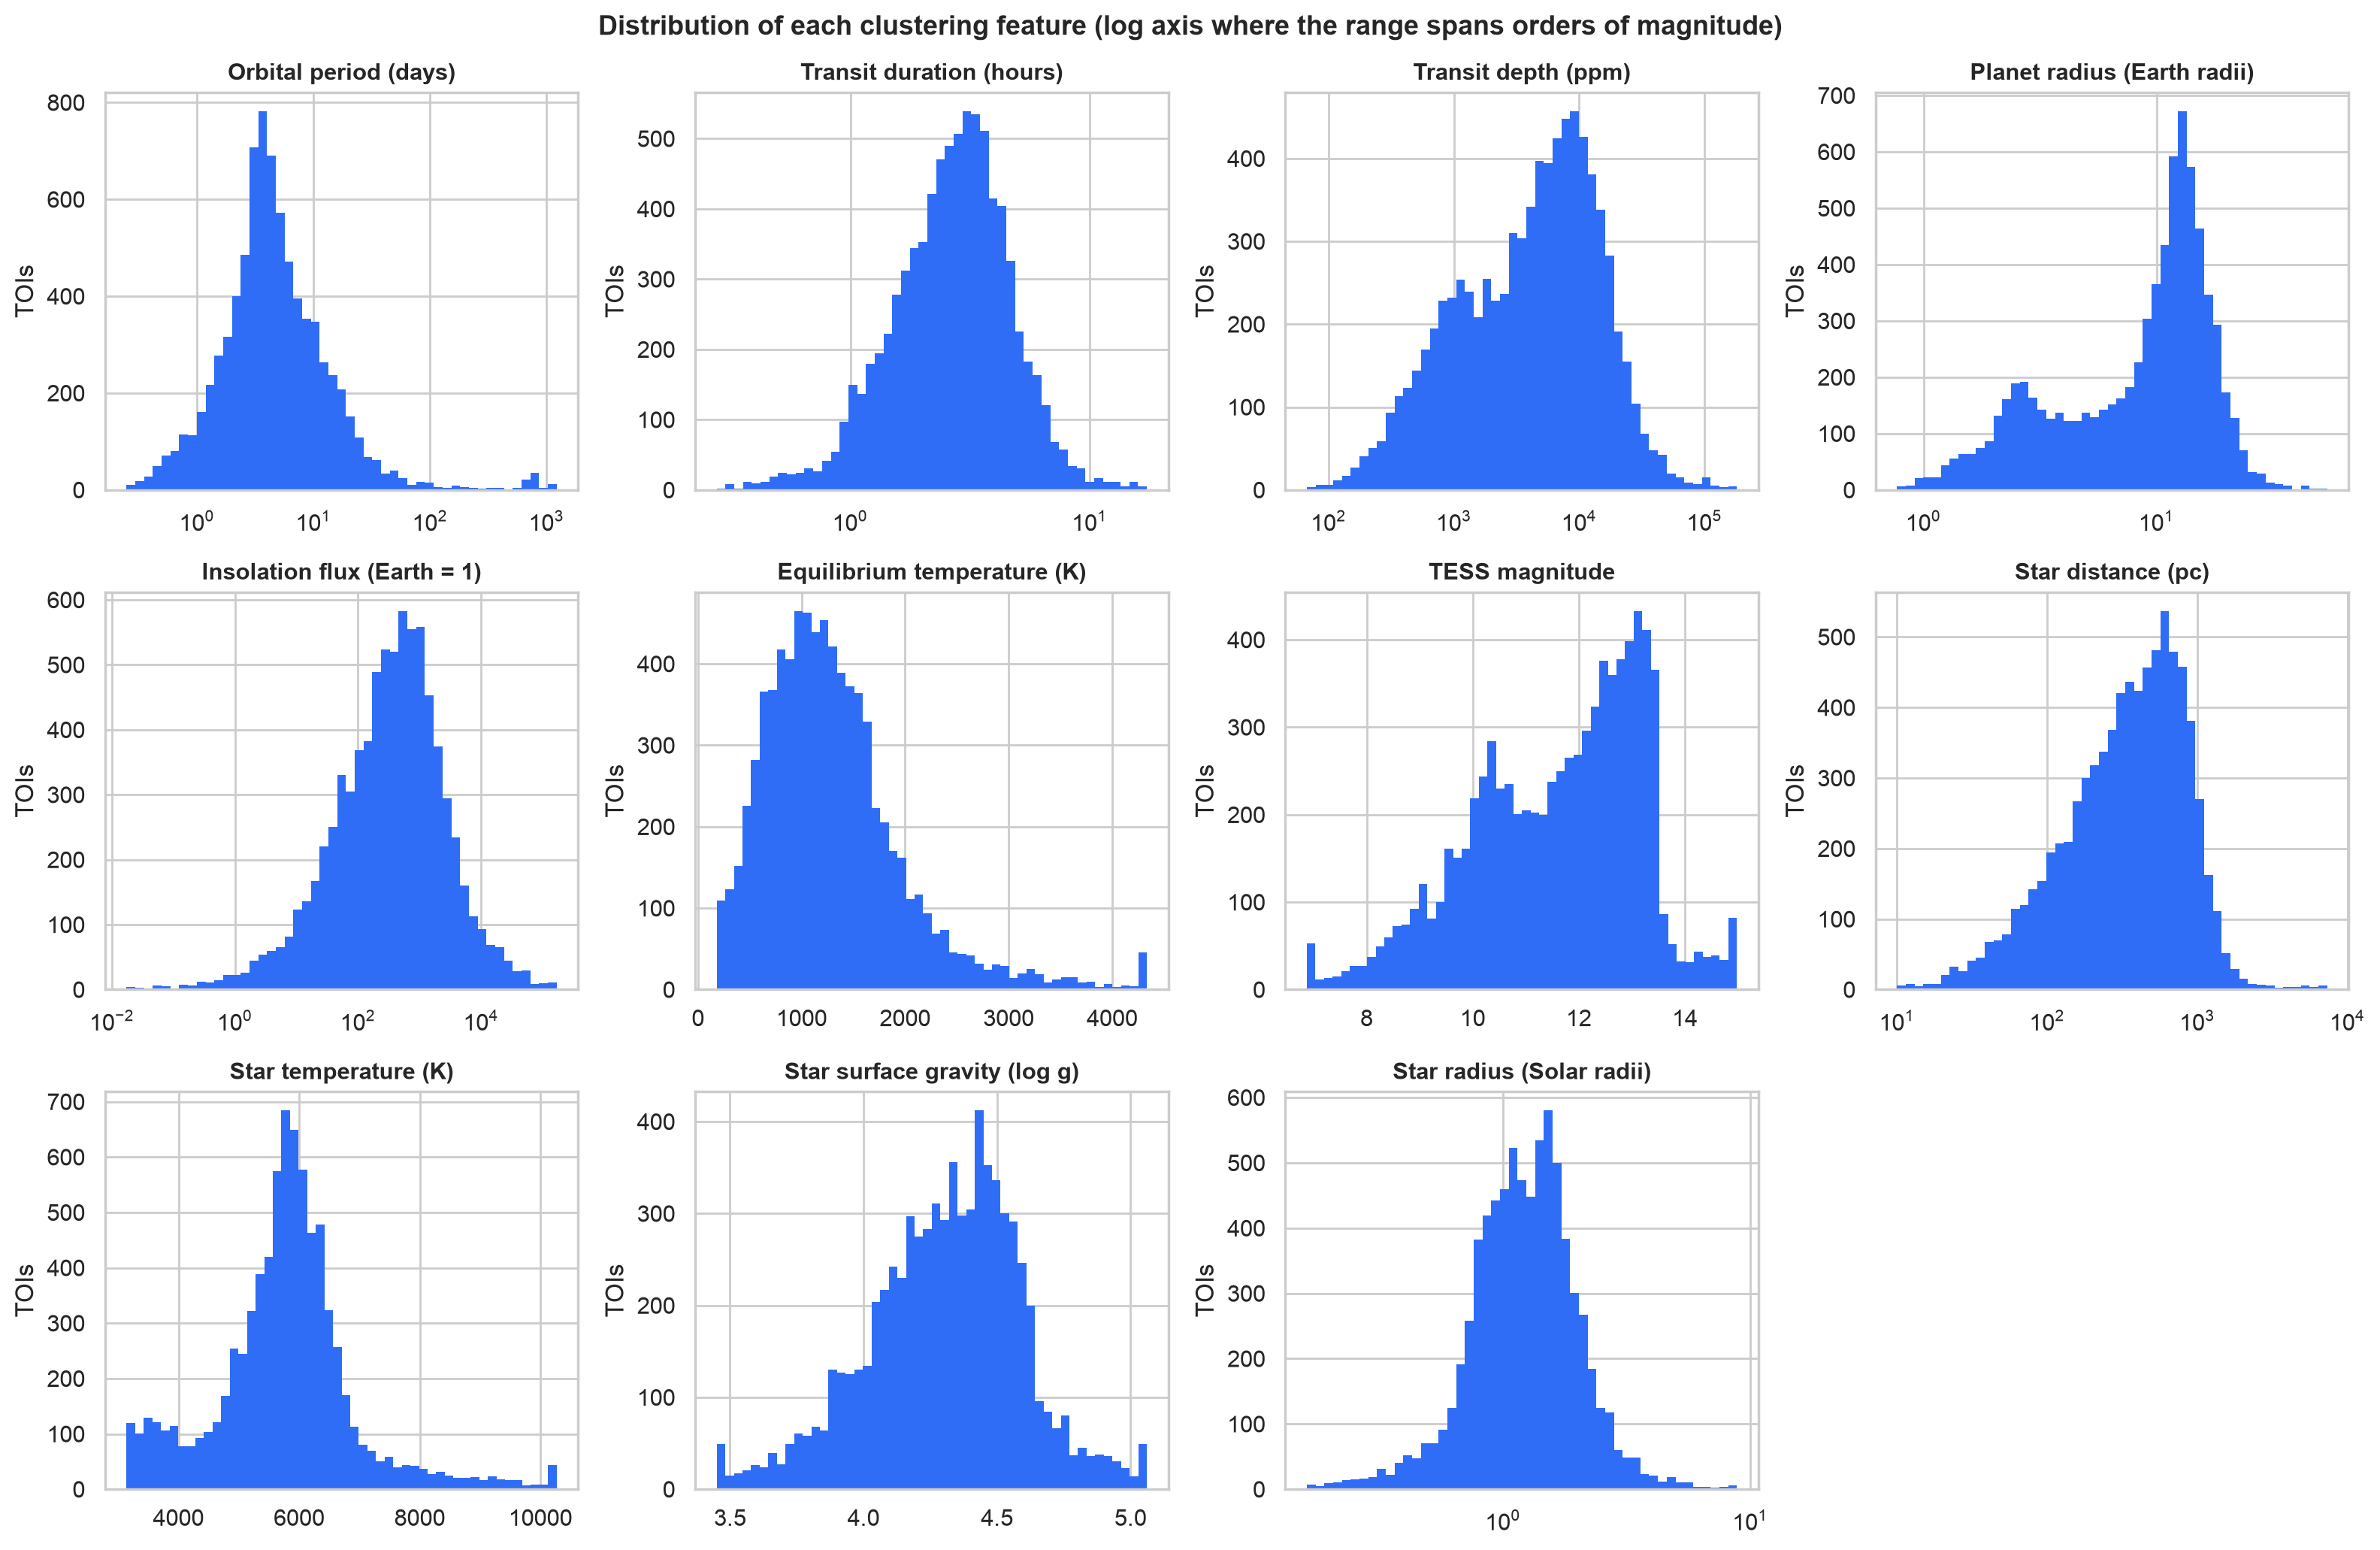

,count,min,50%,max,skew
pl_orbper,8036.0,0.15,4.15,1837.89,10.82
pl_trandurh,8144.0,0.10,2.75,30.02,2.80
pl_trandep,8148.0,24.58,4744.32,767910.31,19.89
pl_rade,7628.0,0.55,10.49,297.11,13.44
pl_insol,7964.0,0.00,378.52,280833.00,13.53
pl_eqt,7834.0,37.00,1194.99,6413.00,1.66
st_tmag,8148.0,4.63,11.89,18.81,-0.51
st_dist,7925.0,6.53,370.79,14728.30,8.76
st_teff,7973.0,2808.00,5799.30,50000.00,9.23
st_logg,7246.0,0.10,4.33,5.96,-0.94


In [3]:
#the eleven measurements used for clustering, with readable names for the plots
FEATURES = {
    'pl_orbper': 'Orbital period (days)',
    'pl_trandurh': 'Transit duration (hours)',
    'pl_trandep': 'Transit depth (ppm)',
    'pl_rade': 'Planet radius (Earth radii)',
    'pl_insol': 'Insolation flux (Earth = 1)',
    'pl_eqt': 'Equilibrium temperature (K)',
    'st_tmag': 'TESS magnitude',
    'st_dist': 'Star distance (pc)',
    'st_teff': 'Star temperature (K)',
    'st_logg': 'Star surface gravity (log g)',
    'st_rad': 'Star radius (Solar radii)',
}
#these span several orders of magnitude, so they are shown and later modelled on a log scale
LOG_FEATURES = ['pl_orbper', 'pl_trandurh', 'pl_trandep', 'pl_rade', 'pl_insol', 'st_dist', 'st_rad']

os.makedirs('figures/Clustering EDA', exist_ok=True)
fig, axes = plt.subplots(3, 4, figsize=(16, 10.5), dpi=200)
for ax, (col, name) in zip(axes.flat, FEATURES.items()):
    s = df[col].dropna()
    if col in LOG_FEATURES:
        s = s[s > 0]
        bins = np.logspace(np.log10(s.quantile(0.001)), np.log10(s.quantile(0.999)), 50)
        ax.hist(s, bins=bins, color='#2f6df6', edgecolor='none')
        ax.set_xscale('log')
    else:
        lo, hi = s.quantile([0.005, 0.995])
        ax.hist(s.clip(lo, hi), bins=50, color='#2f6df6', edgecolor='none')
    ax.set_title(name, fontsize=11, fontweight='bold')
    ax.set_ylabel('TOIs')
axes.flat[-1].axis('off')
fig.suptitle('Distribution of each clustering feature (log axis where the range spans orders of magnitude)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/Clustering EDA/distributions.png', dpi=300, bbox_inches='tight')
plt.show()

summary = df[list(FEATURES)].describe(percentiles=[0.5]).T[['count', 'min', '50%', 'max']]
summary['skew'] = df[list(FEATURES)].skew()
summary.round(2)

**Observation (A2a):** Seven of the measurements span three to six orders of magnitude (period 0.15 to 1,838 days, depth 25 to 768,000 ppm, star radius 0.1 to 102 solar radii) with skew between 3 and 41, so they are plotted, and later modelled, on a log scale, where they look roughly bell-shaped. Planet radius is the one clearly two-humped feature: a small-planet bump around 2 to 3 Earth radii and a much larger one around 10 to 15 Earth radii, Jupiter-sized objects, which is also where eclipsing binaries hide. Equilibrium temperature peaks near 1,000 to 1,500 K and period near 3 to 5 days, because TESS finds hot, short-period objects most easily. Host stars are mostly Sun-like (about 5,800 K, log g 4.0 to 4.7, one solar radius) with a cool-dwarf tail at 3,000 to 4,000 K. The small spike of periods near 700 to 1,000 days is a batch of single-transit TOIs carrying a placeholder period; the 1st/99th percentile clipping in Section B keeps it from forming a cluster of its own.

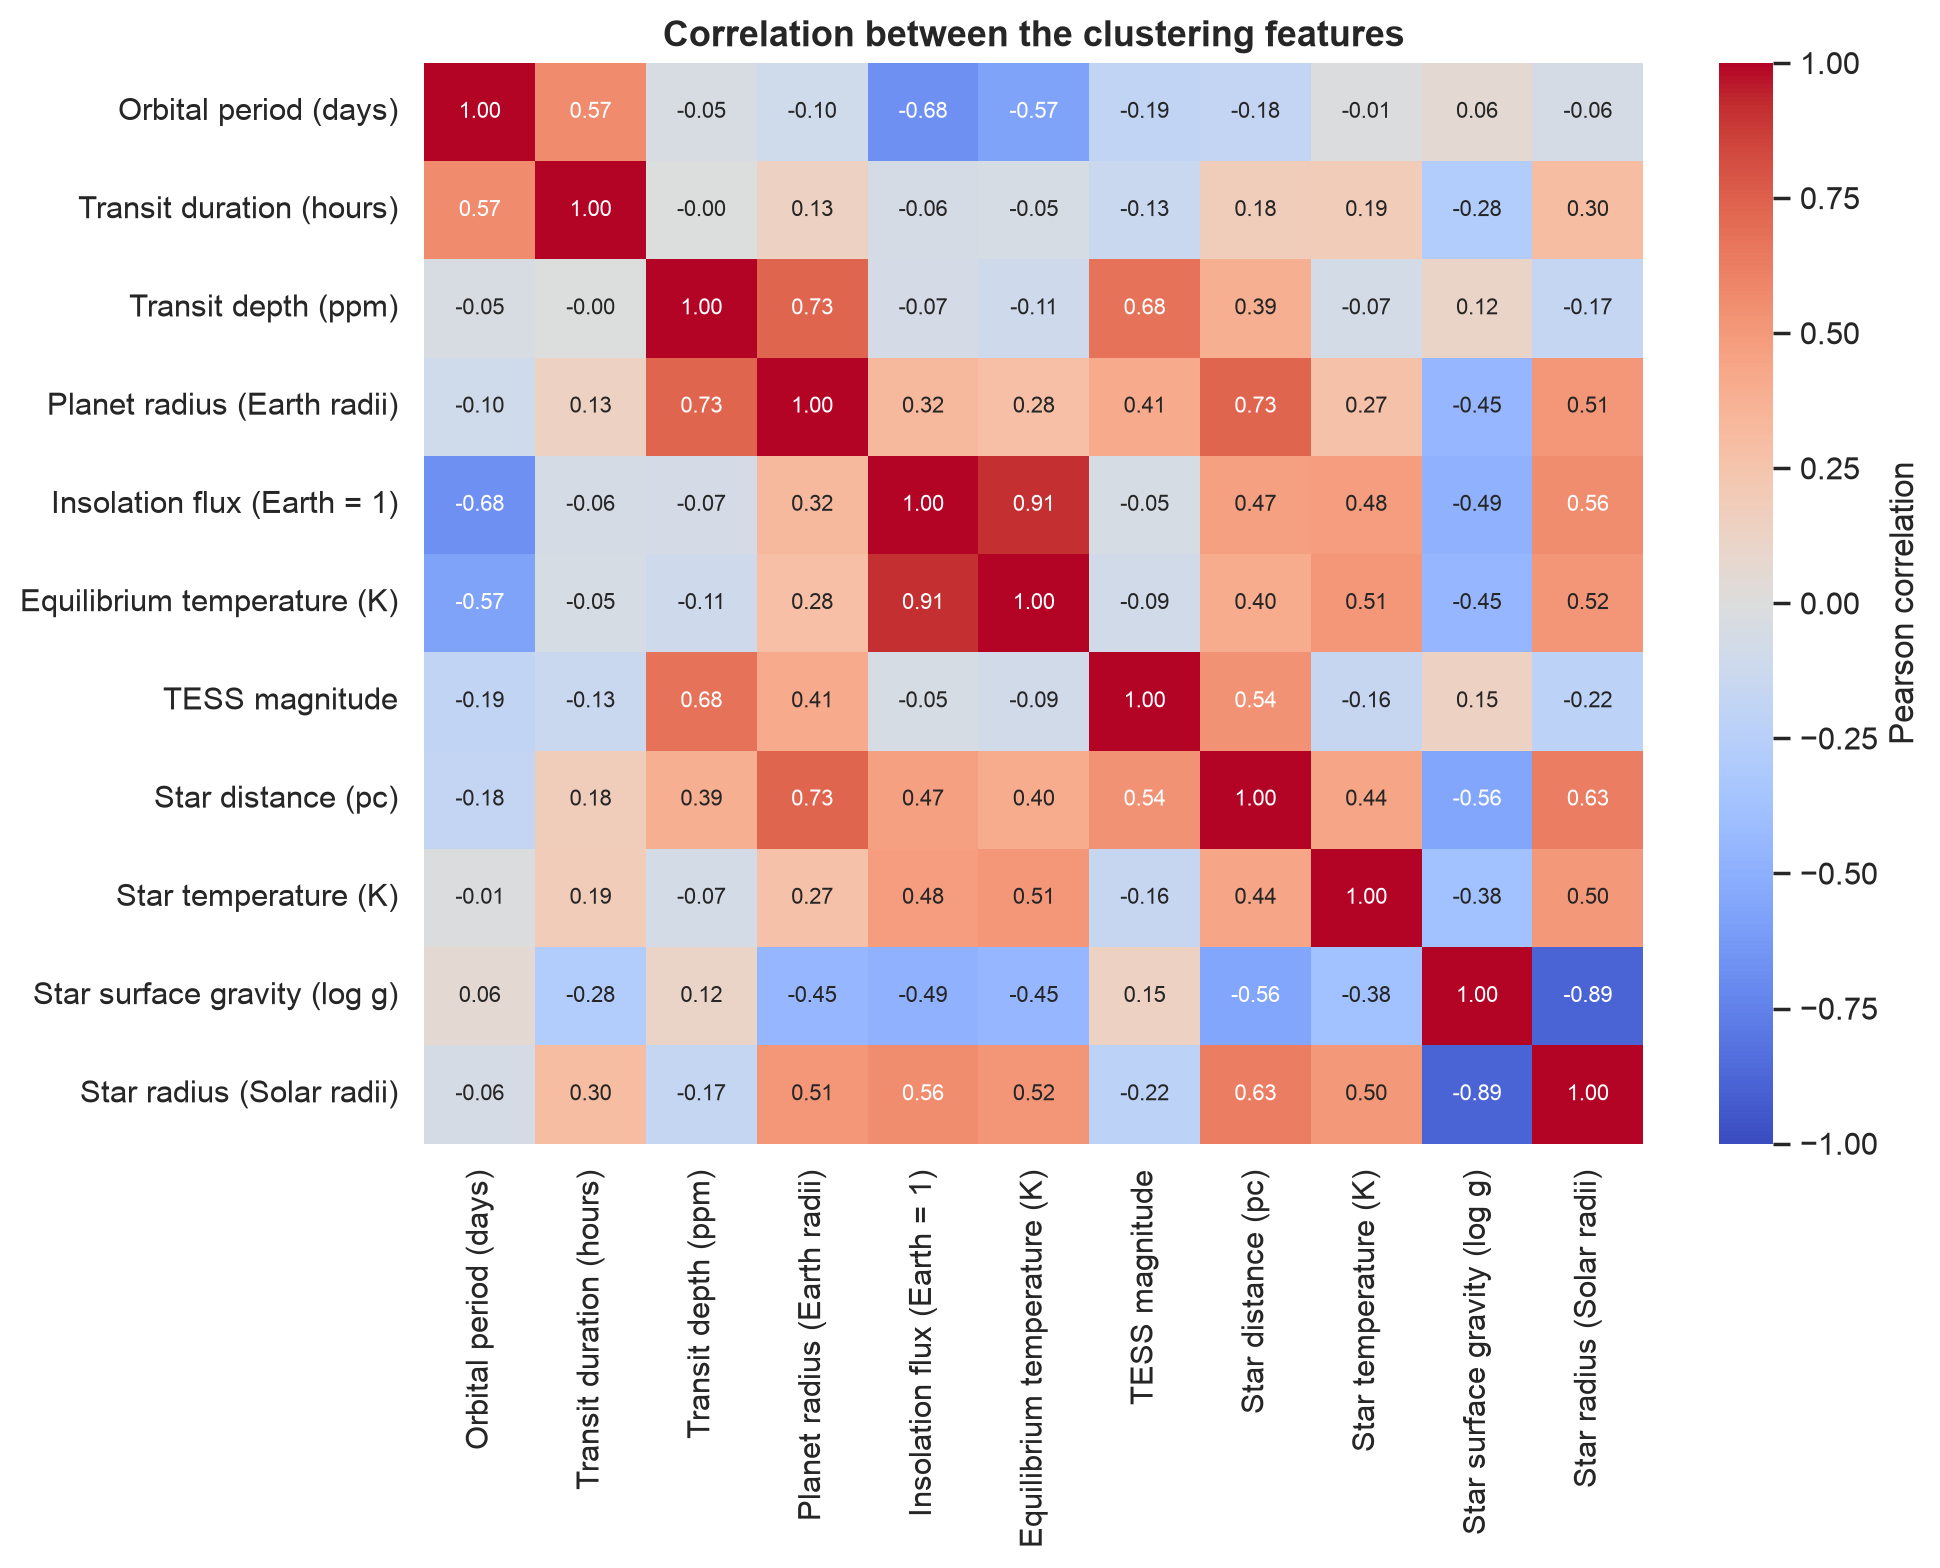

In [4]:
#correlation between the features, on the log scale where one is used, so a few extreme values do not dominate
eda = df[list(FEATURES)].copy()
for col in LOG_FEATURES:
    eda[col] = np.log10(eda[col].where(eda[col] > 0))
corr = eda.corr()

fig, ax = plt.subplots(figsize=(10, 8), dpi=200)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            xticklabels=list(FEATURES.values()), yticklabels=list(FEATURES.values()),
            annot_kws={'size': 8}, cbar_kws={'label': 'Pearson correlation'}, ax=ax)
ax.set_title('Correlation between the clustering features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/Clustering EDA/correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation (A2b):** The features relate the way the physics says they should. Insolation and equilibrium temperature are nearly the same quantity (0.91). Star radius and surface gravity are opposites (-0.89): bigger stars have weaker surface gravity. Transit depth tracks planet radius (0.73) because depth scales with the planet-to-star size ratio, and longer periods mean cooler planets (-0.68 with insolation, -0.57 with temperature). Two correlations are selection effects rather than physics: planet radius rises with star distance (0.73) and depth rises with TESS magnitude (0.68), because on faint, far-away stars only big, deep transits can be detected. This redundancy is why two principal components later capture 63% of the variance.

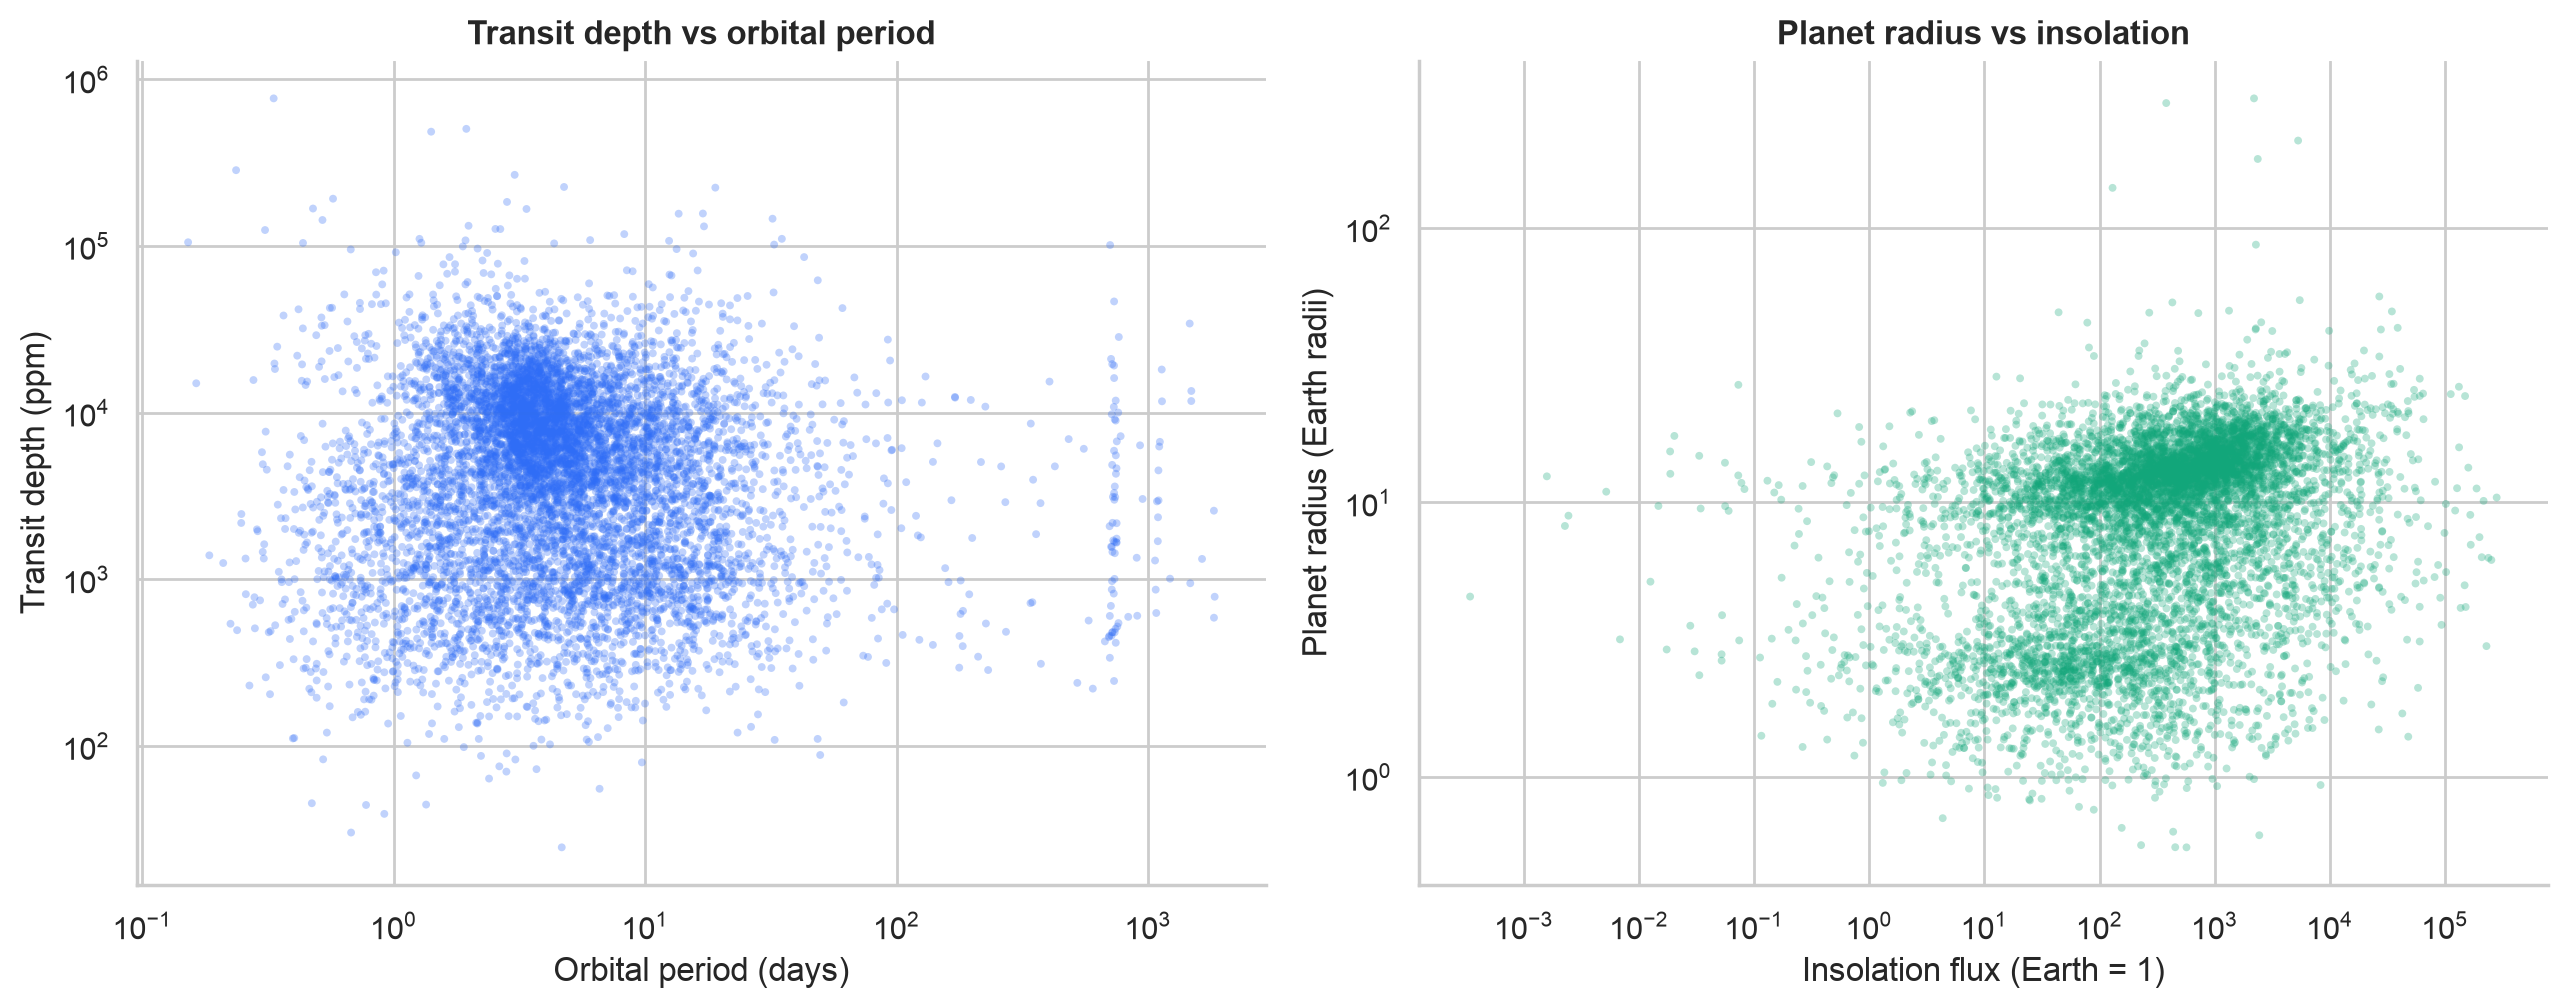

In [5]:
#two feature pairs that physics says should relate: how the signal looks, and how hot the planet is
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), dpi=200)
axes[0].scatter(df['pl_orbper'], df['pl_trandep'], s=8, alpha=0.3, color='#2f6df6', edgecolor='none')
axes[0].set(xscale='log', yscale='log', xlabel='Orbital period (days)', ylabel='Transit depth (ppm)')
axes[0].set_title('Transit depth vs orbital period', fontsize=12, fontweight='bold')
axes[1].scatter(df['pl_insol'], df['pl_rade'], s=8, alpha=0.3, color='#12a67a', edgecolor='none')
axes[1].set(xscale='log', yscale='log', xlabel='Insolation flux (Earth = 1)', ylabel='Planet radius (Earth radii)')
axes[1].set_title('Planet radius vs insolation', fontsize=12, fontweight='bold')
for ax in axes:
    sns.despine(ax=ax)
plt.tight_layout()
plt.savefig('figures/Clustering EDA/feature_scatter.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation (A2c):** Depth against period is one dense cloud at 2 to 10 days and 1,000 to 30,000 ppm with no single trend; the vertical stripe near 700 days is the single-transit placeholder batch seen in the histograms. Radius against insolation shows the two bands from the radius histogram, small planets near 2 to 3 Earth radii and giants near 10 to 15, both spread across insolation from 10 to 10,000 times Earth's. That small-versus-giant split is the clearest natural structure in the data, so it is the first thing a clustering algorithm should find.

## Section B - Preprocessing

Clustering has no target and no held-out test set, so there is no train/test split. The scaler is fitted on all rows, which is not leakage here because nothing is being predicted. The disposition column is set aside and only comes back in the interpretation step.

Steps, in order:

1. keep the eleven physical features, drop identifiers, coordinates, dates and error columns
2. log10 the seven heavy-tailed features (period, duration, depth, planet radius, insolation, distance, star radius); K-Means works on euclidean distance, and without the log a handful of giant values would decide every cluster
3. clip every feature at its 1st and 99th percentile so the few remaining extreme points cannot pull a centroid on their own
4. fill the missing values with the column median
5. standardise with `StandardScaler` so every feature has the same weight in the distance

In [6]:
#labels aside, features in
labels = df['tfopwg_disp'].copy()
X_raw = df[list(FEATURES)].copy()

X_prep = X_raw.copy()
for col in LOG_FEATURES:
    X_prep[col] = np.log10(X_prep[col].where(X_prep[col] > 0))  #non-positive values become missing and are imputed below
for col in X_prep.columns:
    lo, hi = X_prep[col].quantile([0.01, 0.99])
    X_prep[col] = X_prep[col].clip(lo, hi)

imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(imputer.fit_transform(X_prep), columns=X_prep.columns, index=X_prep.index)
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(X_imputed), columns=X_prep.columns, index=X_prep.index)

print(f"Clustering matrix: {X.shape[0]:,} rows x {X.shape[1]} features, missing values: {int(X.isna().sum().sum())}")
check = pd.DataFrame({'skew before': X_raw.skew().round(2), 'skew after log + clip': X_imputed.skew().round(2),
                      'mean after scaling': X.mean().round(2), 'std after scaling': X.std().round(2)})
check

Clustering matrix: 8,148 rows x 11 features, missing values: 0


,skew before,skew after log + clip,mean after scaling,std after scaling
pl_orbper,10.82,1.14,0.0,1.0
pl_trandurh,2.80,-0.37,0.0,1.0
pl_trandep,19.89,-0.37,0.0,1.0
pl_rade,13.44,-0.86,-0.0,1.0
pl_insol,13.53,-0.43,-0.0,1.0
pl_eqt,1.66,1.23,-0.0,1.0
st_tmag,-0.51,-0.47,-0.0,1.0
st_dist,8.76,-0.66,-0.0,1.0
st_teff,9.23,0.41,0.0,1.0
st_logg,-0.94,-0.33,-0.0,1.0


## Section C - K-Means Clustering

### C1. What is K-Means?

K-Means splits the rows into `k` groups by placing `k` centre points (centroids) and moving them until every row sits with its nearest centre.

- **How it learns:** start with `k` centroids (k-means++ spreads the starting points out), assign each row to its nearest centroid, move each centroid to the mean of its rows, repeat until nothing changes. `n_init=10` runs that from ten different starts and keeps the best.
- **Inertia:** the sum of squared distances from every row to its centroid. Lower is tighter, and it always falls as `k` grows, which is why the elbow matters.
- **Elbow curve:** inertia against `k`. The bend is where adding another cluster stops buying much.
- **Silhouette:** for each row, how close it is to its own cluster compared with the nearest other cluster, from -1 to 1. Averaged over all rows it scores a whole clustering, so it is a second opinion on `k`.
- **Why scaling:** distance mixes every feature at once, so without Section B a star's distance in parsecs would outweigh everything else.
- **Limits:** it assumes roughly round clusters of similar size, needs `k` chosen by hand, and is pulled by outliers, which is why the features were logged and clipped.

### C2. Choosing k

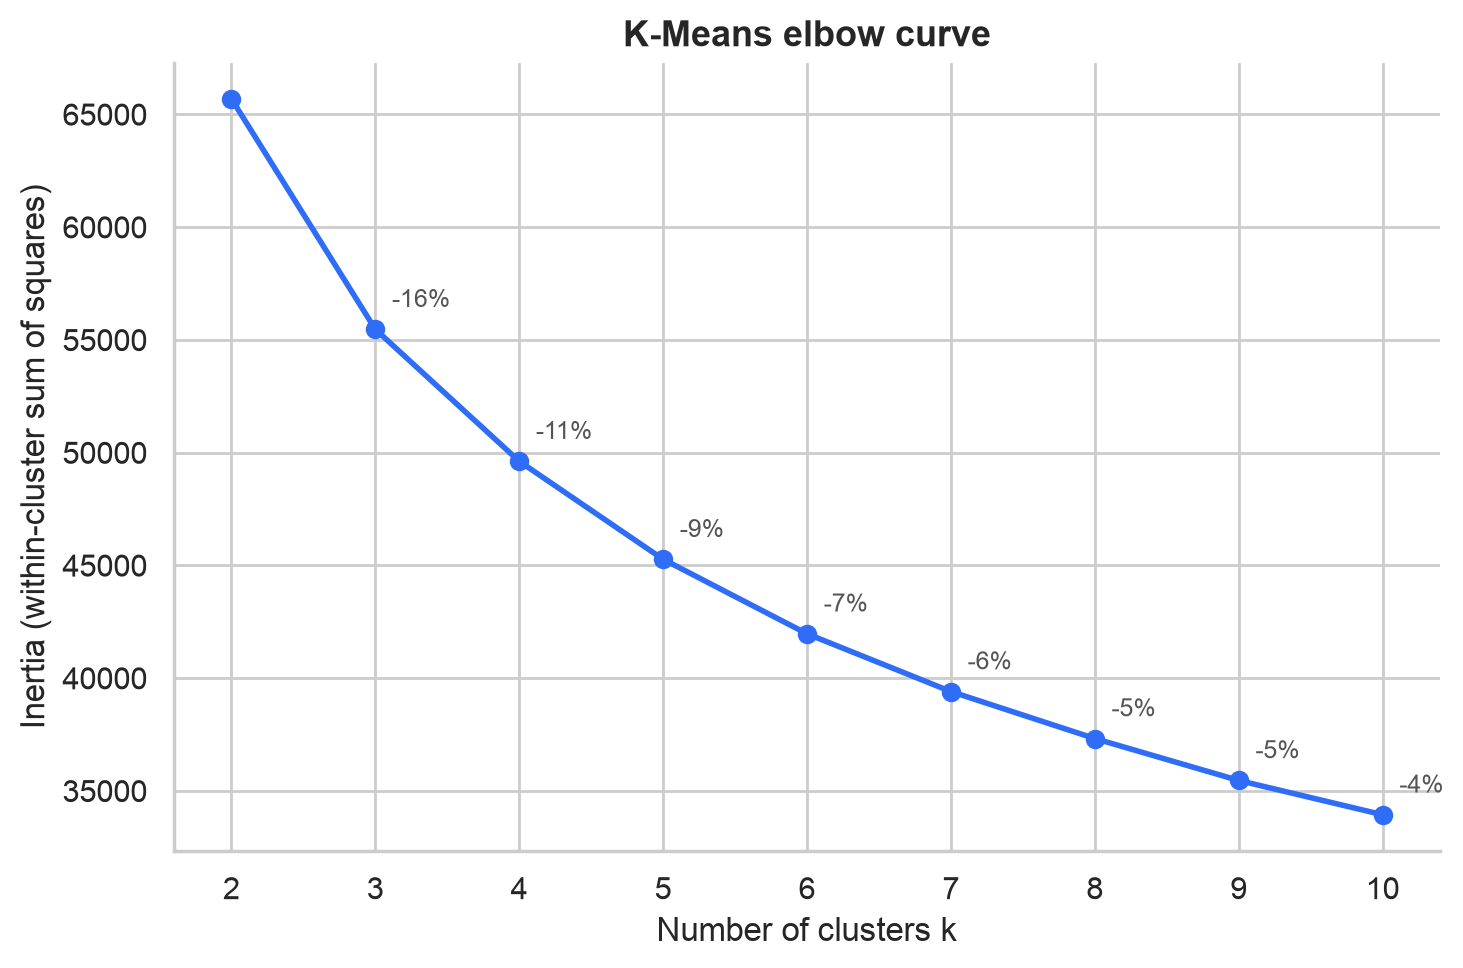

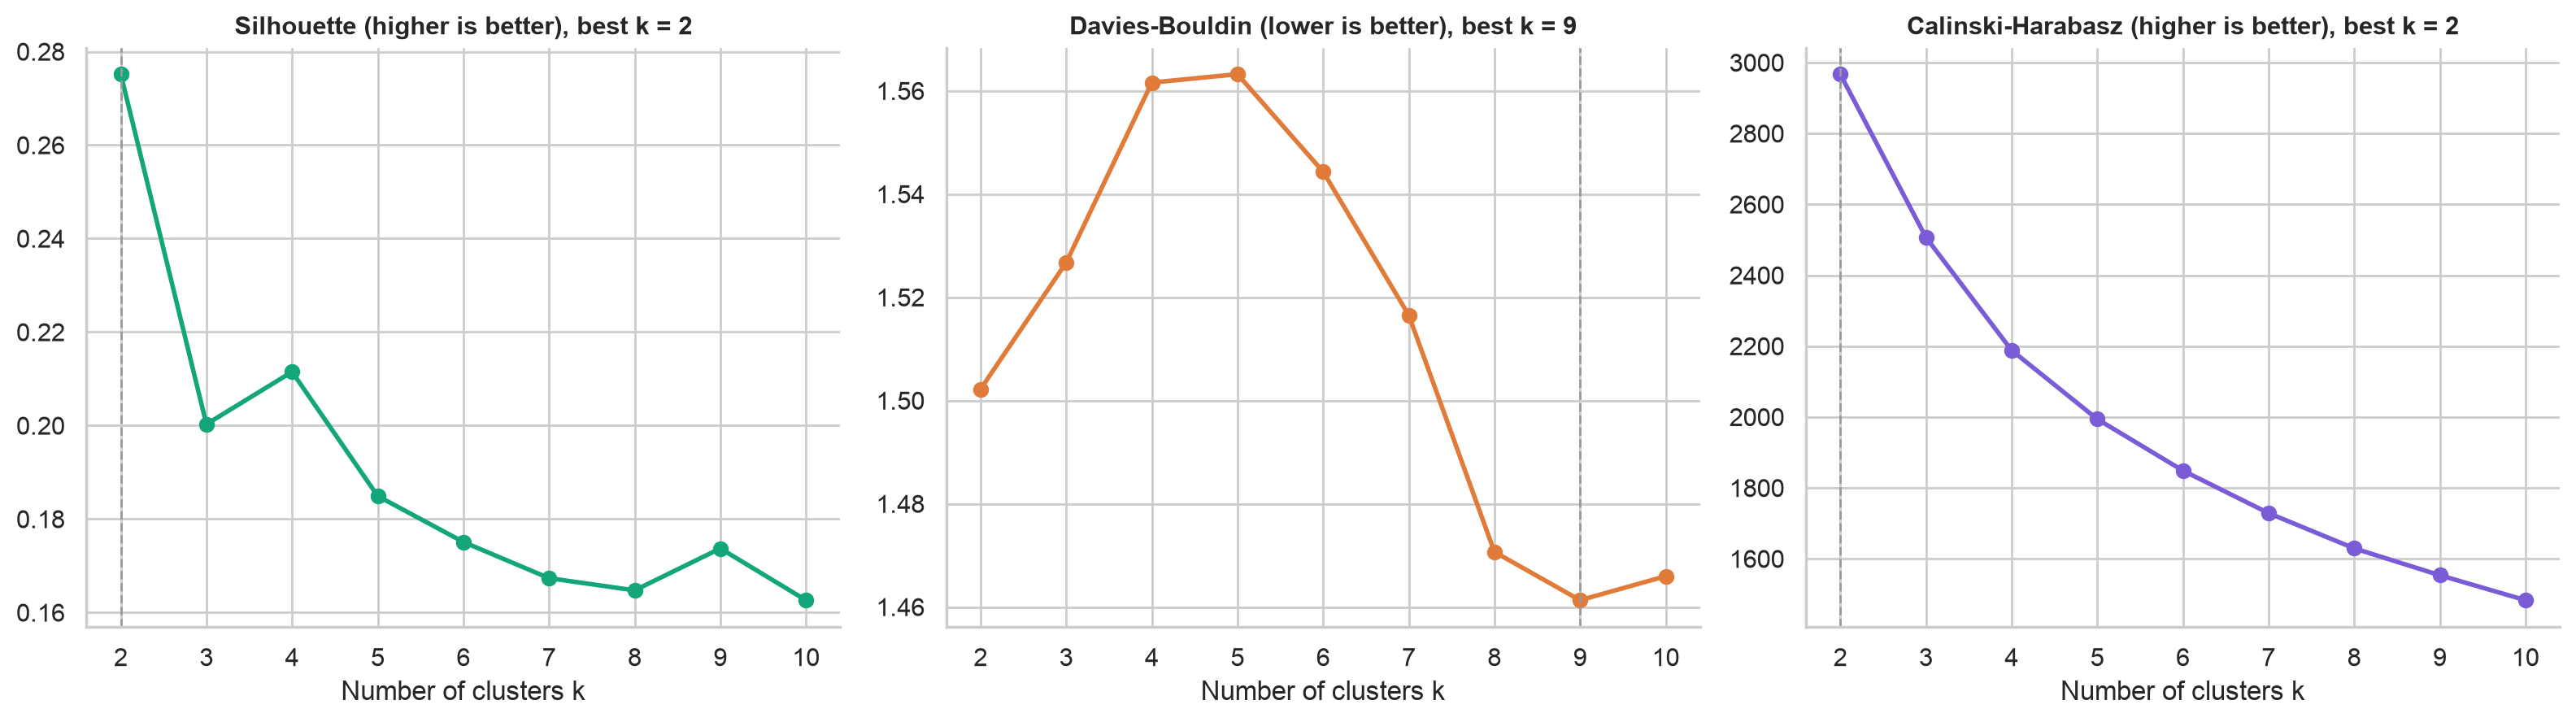

Best k by silhouette: 2 | by Davies-Bouldin: 9 | by Calinski-Harabasz: 2


,k,inertia,inertia drop (%),silhouette,davies_bouldin,calinski_harabasz
0,2,65696.6916,NaN,0.2752,1.5022,2967.3419
1,3,55476.4493,15.6,0.2003,1.5267,2507.0579
2,4,49623.3407,10.6,0.2115,1.5616,2188.4782
3,5,45275.1151,8.8,0.1849,1.5632,1994.2920
4,6,41971.6987,7.3,0.1751,1.5443,1848.9590
5,7,39408.9547,6.1,0.1674,1.5165,1729.0229
6,8,37324.9030,5.3,0.1648,1.4707,1629.5117
7,9,35465.9524,5.0,0.1737,1.4613,1553.6911
8,10,33945.4531,4.3,0.1626,1.4660,1483.2477


In [7]:
#sweep k: inertia for the elbow, plus the three internal metrics so the choice of k does not rest on one number
ks = range(2, 11)
sweep = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    sweep.append({'k': k, 'inertia': km.inertia_,
                  'silhouette': silhouette_score(X, km.labels_),
                  'davies_bouldin': davies_bouldin_score(X, km.labels_),
                  'calinski_harabasz': calinski_harabasz_score(X, km.labels_)})
sweep = pd.DataFrame(sweep)
sweep.insert(2, 'inertia drop (%)', (-sweep['inertia'].pct_change() * 100).round(1))

os.makedirs('figures/K-Means', exist_ok=True)
fig, ax = plt.subplots(figsize=(7.5, 5), dpi=200)
ax.plot(sweep['k'], sweep['inertia'], marker='o', color='#2f6df6', lw=2)
for k, drop in zip(sweep['k'][1:], sweep['inertia drop (%)'][1:]):
    ax.annotate(f'-{drop:.0f}%', (k, sweep.loc[sweep['k'] == k, 'inertia'].iloc[0]), textcoords='offset points', xytext=(6, 8), fontsize=9, color='#555')
ax.set(xlabel='Number of clusters k', ylabel='Inertia (within-cluster sum of squares)', xticks=list(ks))
ax.set_title('K-Means elbow curve', fontsize=13, fontweight='bold')
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig('figures/K-Means/elbow_curve.png', dpi=300, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), dpi=200)
for ax, (metric, title, color, best) in zip(axes, [
        ('silhouette', 'Silhouette (higher is better)', '#12a67a', 'max'),
        ('davies_bouldin', 'Davies-Bouldin (lower is better)', '#e07b39', 'min'),
        ('calinski_harabasz', 'Calinski-Harabasz (higher is better)', '#7a5cd6', 'max')]):
    ax.plot(sweep['k'], sweep[metric], marker='o', color=color, lw=2)
    kbest = int(sweep.loc[getattr(sweep[metric], 'idx' + best)(), 'k'])
    ax.axvline(kbest, color='#999', ls='--', lw=1)
    ax.set(xlabel='Number of clusters k', xticks=list(ks))
    ax.set_title(f'{title}, best k = {kbest}', fontsize=11, fontweight='bold')
    sns.despine(ax=ax)
plt.tight_layout()
plt.savefig('figures/K-Means/k_selection_metrics.png', dpi=300, bbox_inches='tight')
plt.show()

print("Best k by silhouette:", int(sweep.loc[sweep['silhouette'].idxmax(), 'k']),
      "| by Davies-Bouldin:", int(sweep.loc[sweep['davies_bouldin'].idxmin(), 'k']),
      "| by Calinski-Harabasz:", int(sweep.loc[sweep['calinski_harabasz'].idxmax(), 'k']))
sweep.round(4)

**Observation (C2):** Silhouette and Calinski-Harabasz both point to k = 2: silhouette is highest there (0.275) and so is Calinski-Harabasz (2,967), and both fall steadily as k grows. Davies-Bouldin is almost flat, between 1.46 and 1.56 for every k, and its minimum at k = 9 is a weak preference for many small, compact clusters rather than a sign of real structure. The elbow curve has no sharp bend: inertia falls 15.6% going from 2 to 3 clusters, 10.6% to 4, then under 9% per extra cluster, so the elbow reads as 3 to 4 at most. Silhouette has a second, smaller peak at k = 4 (0.212), so k = 4 is kept as a finer view in C4. The reported model uses k = 2, the value the two decisive metrics agree on and the simplest structure the data supports.

### C3. Final model

In [8]:
K_CHOSEN = 2
k_final = K_CHOSEN or int(sweep.loc[sweep['silhouette'].idxmax(), 'k'])

kmeans = KMeans(n_clusters=k_final, n_init=10, random_state=RANDOM_STATE).fit(X)
km_labels = pd.Series(kmeans.labels_, index=X.index, name='kmeans_cluster')
print(f"K-Means with k = {k_final}: inertia {kmeans.inertia_:.1f}, converged in {kmeans.n_iter_} iterations")
print("Cluster sizes:", km_labels.value_counts().sort_index().to_dict())

#shared containers: the agglomerative section appends to these so sections e and f compare both algorithms
cluster_results = []
cluster_labels = {}

def score_clustering(name, lab):
    row = {'Algorithm': name, 'Clusters': int(pd.Series(lab).nunique()),
           'Silhouette': silhouette_score(X, lab),
           'Davies-Bouldin': davies_bouldin_score(X, lab),
           'Calinski-Harabasz': calinski_harabasz_score(X, lab)}
    cluster_results[:] = [r for r in cluster_results if r['Algorithm'] != name]
    cluster_results.append(row)
    cluster_labels[name] = pd.Series(lab, index=X.index)
    return row

km_scores = score_clustering('K-Means', km_labels)
pd.DataFrame([km_scores]).round(4)

K-Means with k = 2: inertia 65696.7, converged in 10 iterations
Cluster sizes: {0: 2807, 1: 5341}


,Algorithm,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means,2,0.2752,1.5022,2967.3419


PC1 explains 40.5% of the variance, PC2 22.5%, together 63.1%


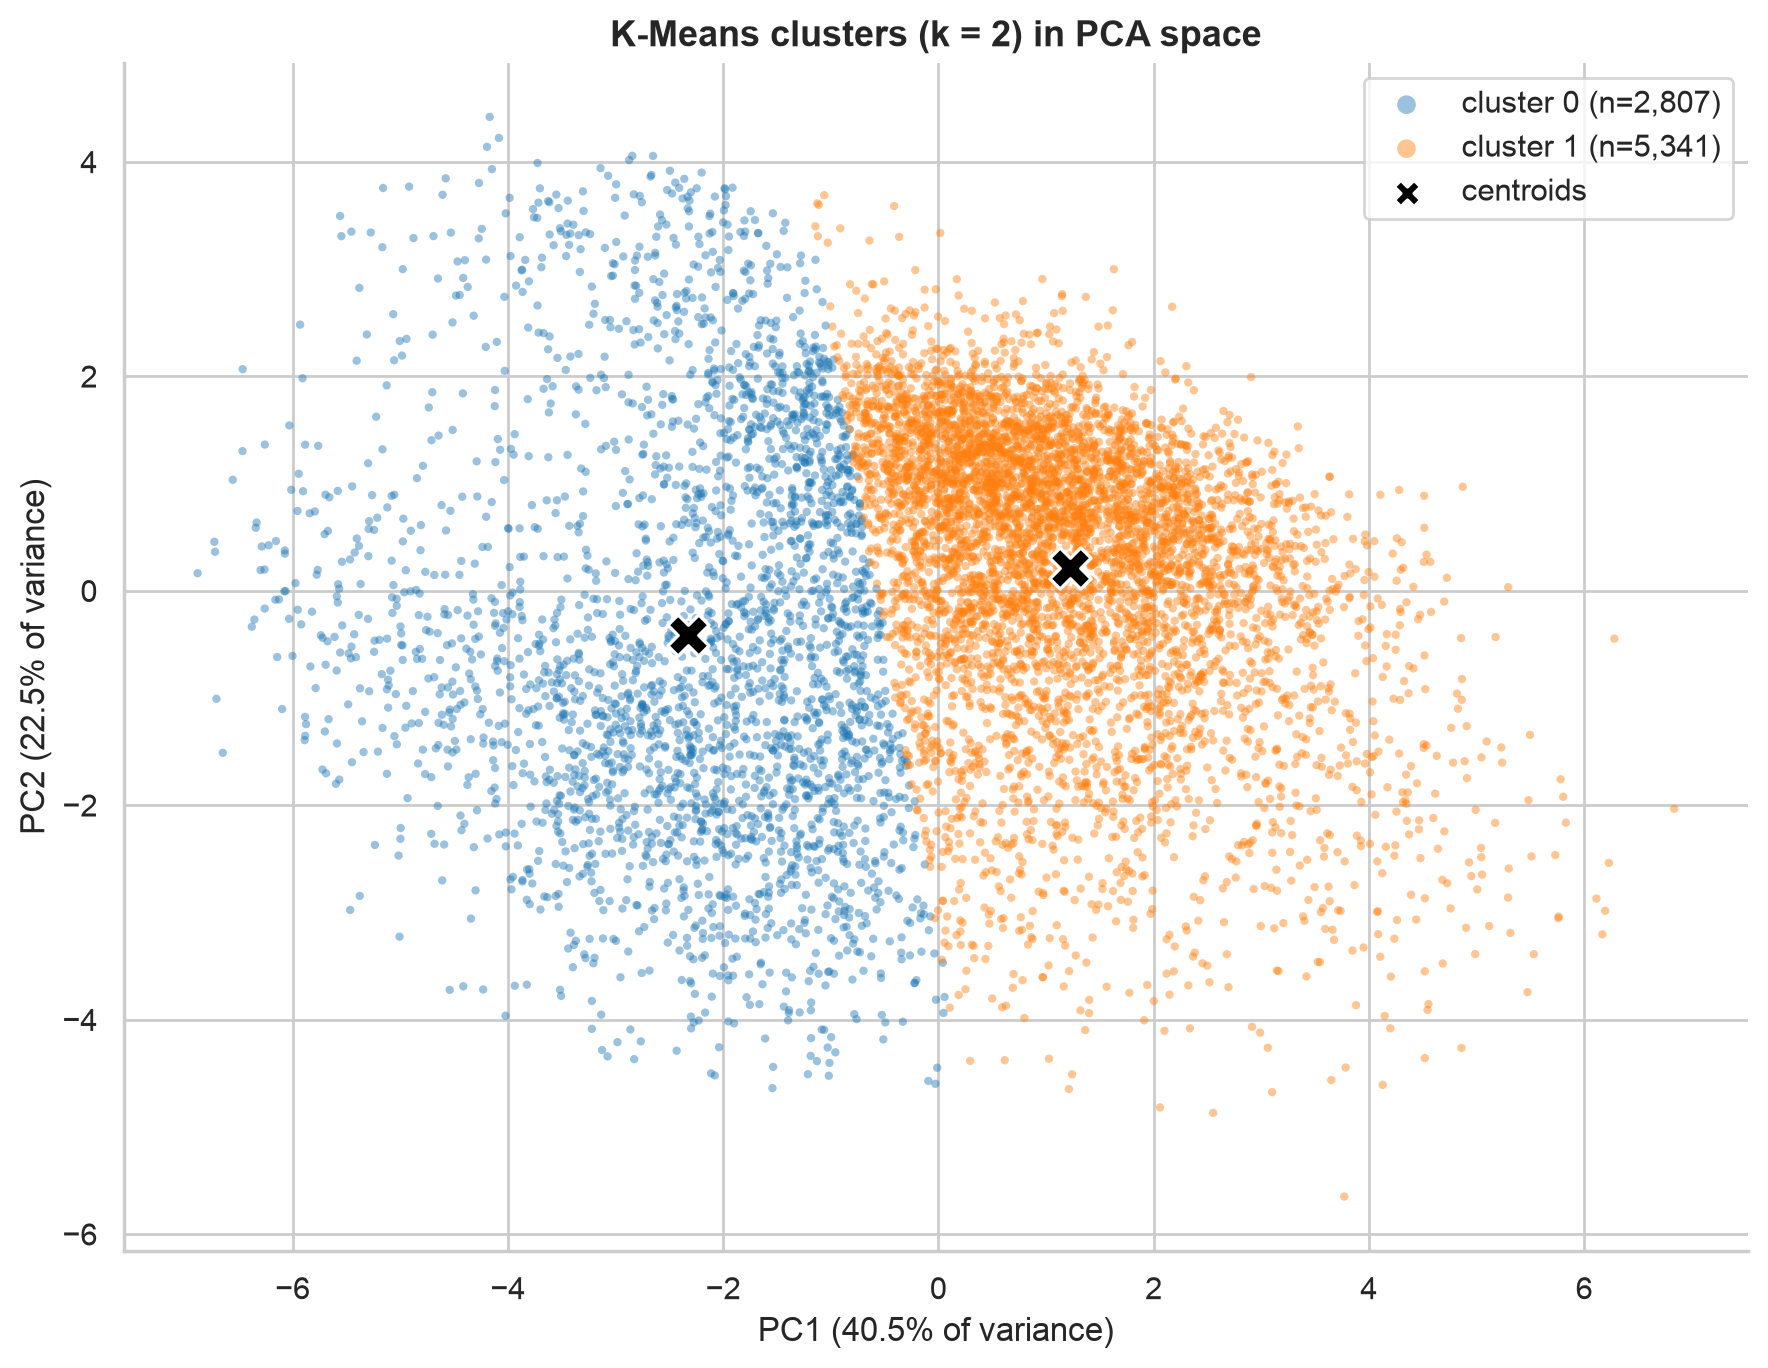

,PC1,PC2
Orbital period (days),-0.17,-0.06
Transit duration (hours),0.08,-0.08
Transit depth (ppm),0.06,0.58
Planet radius (Earth radii),0.31,0.38
Insolation flux (Earth = 1),0.39,-0.11
Equilibrium temperature (K),0.37,-0.14
TESS magnitude,0.03,0.56
Star distance (pc),0.37,0.28
Star temperature (K),0.36,-0.18
Star surface gravity (log g),-0.37,0.14


In [9]:
#pca to two components, fitted on the scaled features, used only to draw the clusters
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
centroids_pca = pca.transform(pd.DataFrame(kmeans.cluster_centers_, columns=X.columns))
ev = pca.explained_variance_ratio_ * 100
print(f"PC1 explains {ev[0]:.1f}% of the variance, PC2 {ev[1]:.1f}%, together {ev.sum():.1f}%")

loadings = pd.DataFrame(pca.components_.T, index=list(FEATURES.values()), columns=['PC1', 'PC2']).round(2)

fig, ax = plt.subplots(figsize=(9, 7), dpi=200)
palette = sns.color_palette('tab10', k_final)
for c in range(k_final):
    m = km_labels == c
    ax.scatter(X_pca[m, 0], X_pca[m, 1], s=9, alpha=0.45, color=palette[c], edgecolor='none', label=f'cluster {c} (n={m.sum():,})')
ax.scatter(centroids_pca[:, 0], centroids_pca[:, 1], s=220, marker='X', color='black', edgecolor='white', linewidth=1.2, label='centroids', zorder=5)
ax.set_xlabel(f'PC1 ({ev[0]:.1f}% of variance)')
ax.set_ylabel(f'PC2 ({ev[1]:.1f}% of variance)')
ax.set_title(f'K-Means clusters (k = {k_final}) in PCA space', fontsize=13, fontweight='bold')
leg = ax.legend(frameon=True)
for handle, size in zip(leg.legend_handles, [45] * k_final + [90]):  #readable point markers, centroid marker kept modest
    handle.set_sizes([size])
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig('figures/K-Means/pca_clusters.png', dpi=300, bbox_inches='tight')
plt.show()
loadings

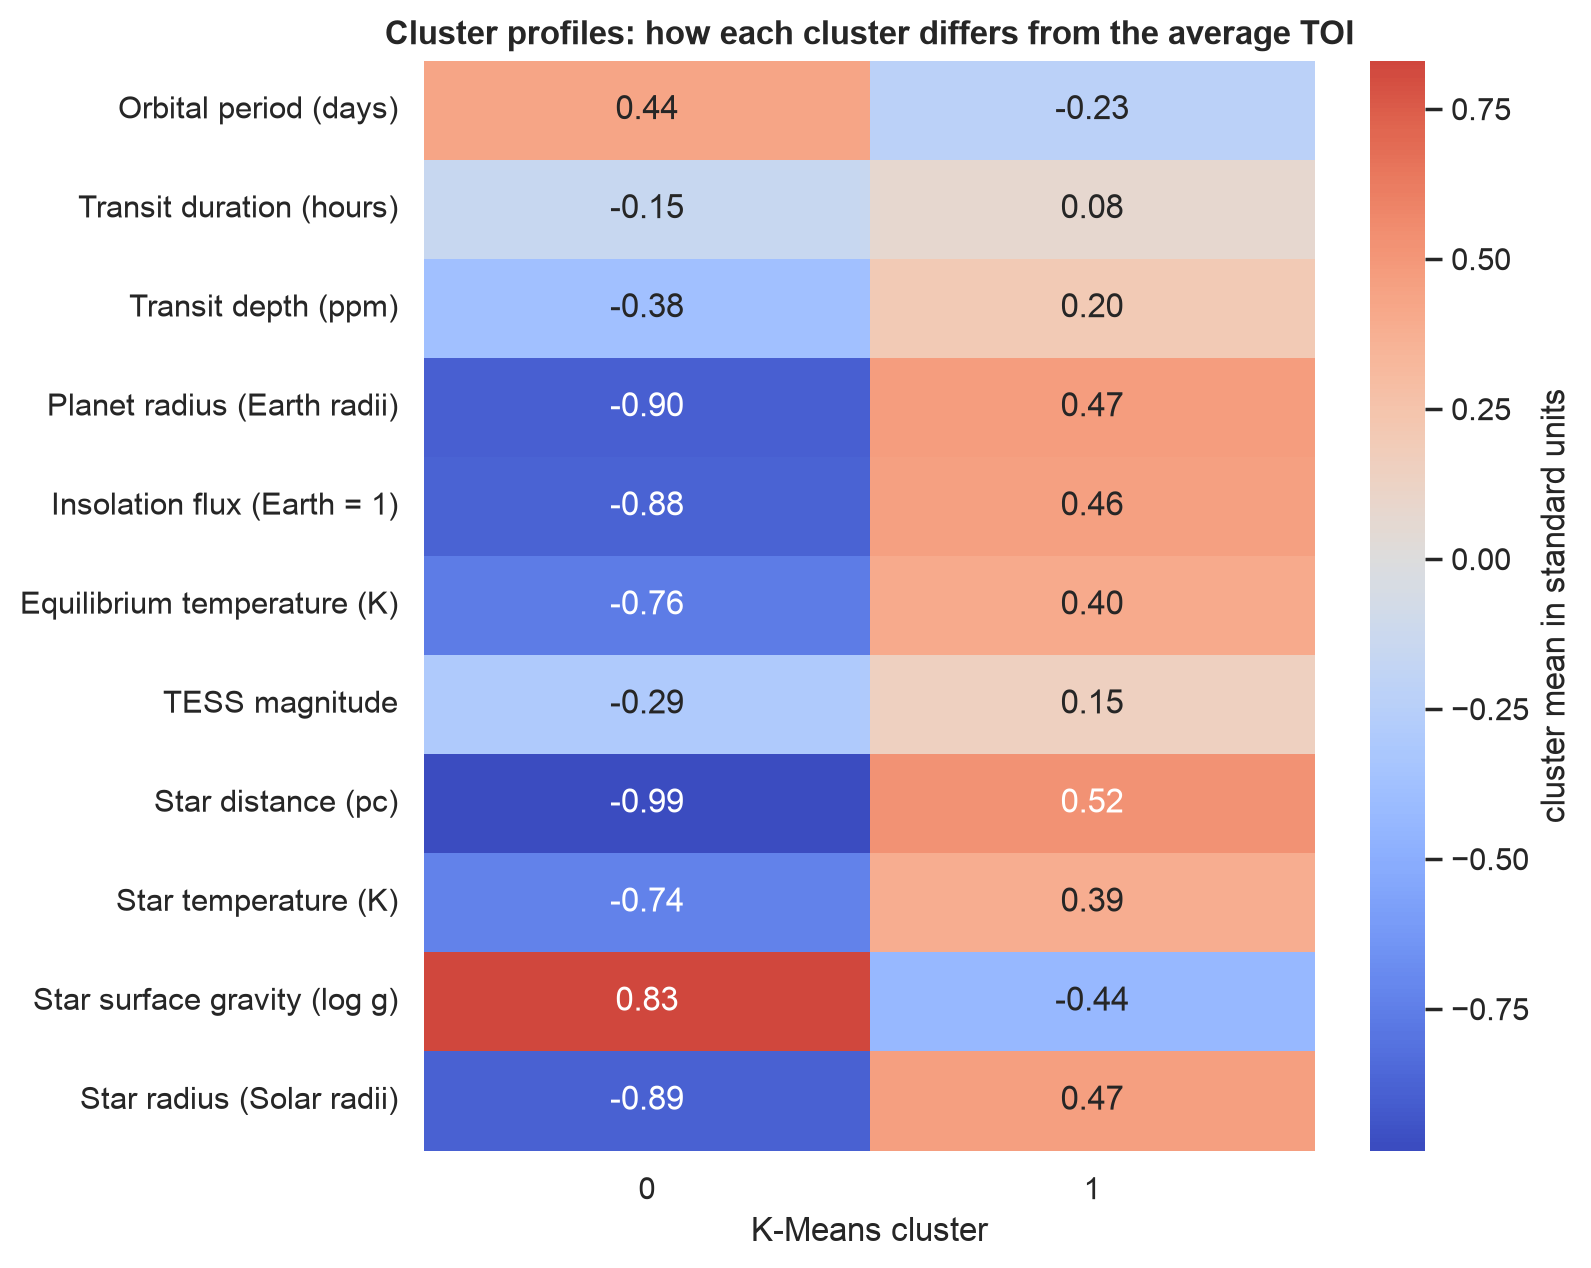

,cluster 0,cluster 1,overall median
Orbital period (days),7.06,3.61,4.15
Transit duration (hours),2.48,2.90,2.75
Transit depth (ppm),1700.00,6065.00,4744.32
Planet radius (Earth radii),3.45,12.71,10.49
Insolation flux (Earth = 1),56.43,796.31,378.52
Equilibrium temperature (K),740.00,1441.00,1194.99
TESS magnitude,11.05,12.23,11.89
Star distance (pc),137.20,557.33,370.79
Star temperature (K),5078.00,6046.53,5799.30
Star surface gravity (log g),4.53,4.20,4.33


In [10]:
#what each cluster looks like in the original units (medians), and which features separate them most
profile = X_raw.assign(cluster=km_labels).groupby('cluster').median().T
profile.index = [FEATURES[c] for c in profile.index]
profile.columns = [f'cluster {c}' for c in profile.columns]
profile['overall median'] = X_raw.median().values

#standardised cluster means show the separation per feature on one colour scale
zmeans = X.assign(cluster=km_labels).groupby('cluster').mean().T
zmeans.index = [FEATURES[c] for c in zmeans.index]
fig, ax = plt.subplots(figsize=(8, 6.5), dpi=200)
sns.heatmap(zmeans, annot=True, fmt='.2f', cmap='coolwarm', center=0, cbar_kws={'label': 'cluster mean in standard units'}, ax=ax)
ax.set_xlabel('K-Means cluster')
ax.set_title('Cluster profiles: how each cluster differs from the average TOI', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/K-Means/cluster_profiles.png', dpi=300, bbox_inches='tight')
plt.show()
profile.round(2)

### C4. Results and interpretation

Only now do the labels come in, to read what the clusters contain. They played no part in the fitting.

Rows per cluster and disposition group:


tfopwg_disp,candidate,not a planet,planet,unknown
kmeans_cluster,,,,
0,1678,325,804,0
1,3634,1089,616,2


Share of each cluster (%):


tfopwg_disp,candidate,not a planet,planet,unknown
kmeans_cluster,,,,
0,59.8,11.6,28.6,0.0
1,68.0,20.4,11.5,0.0


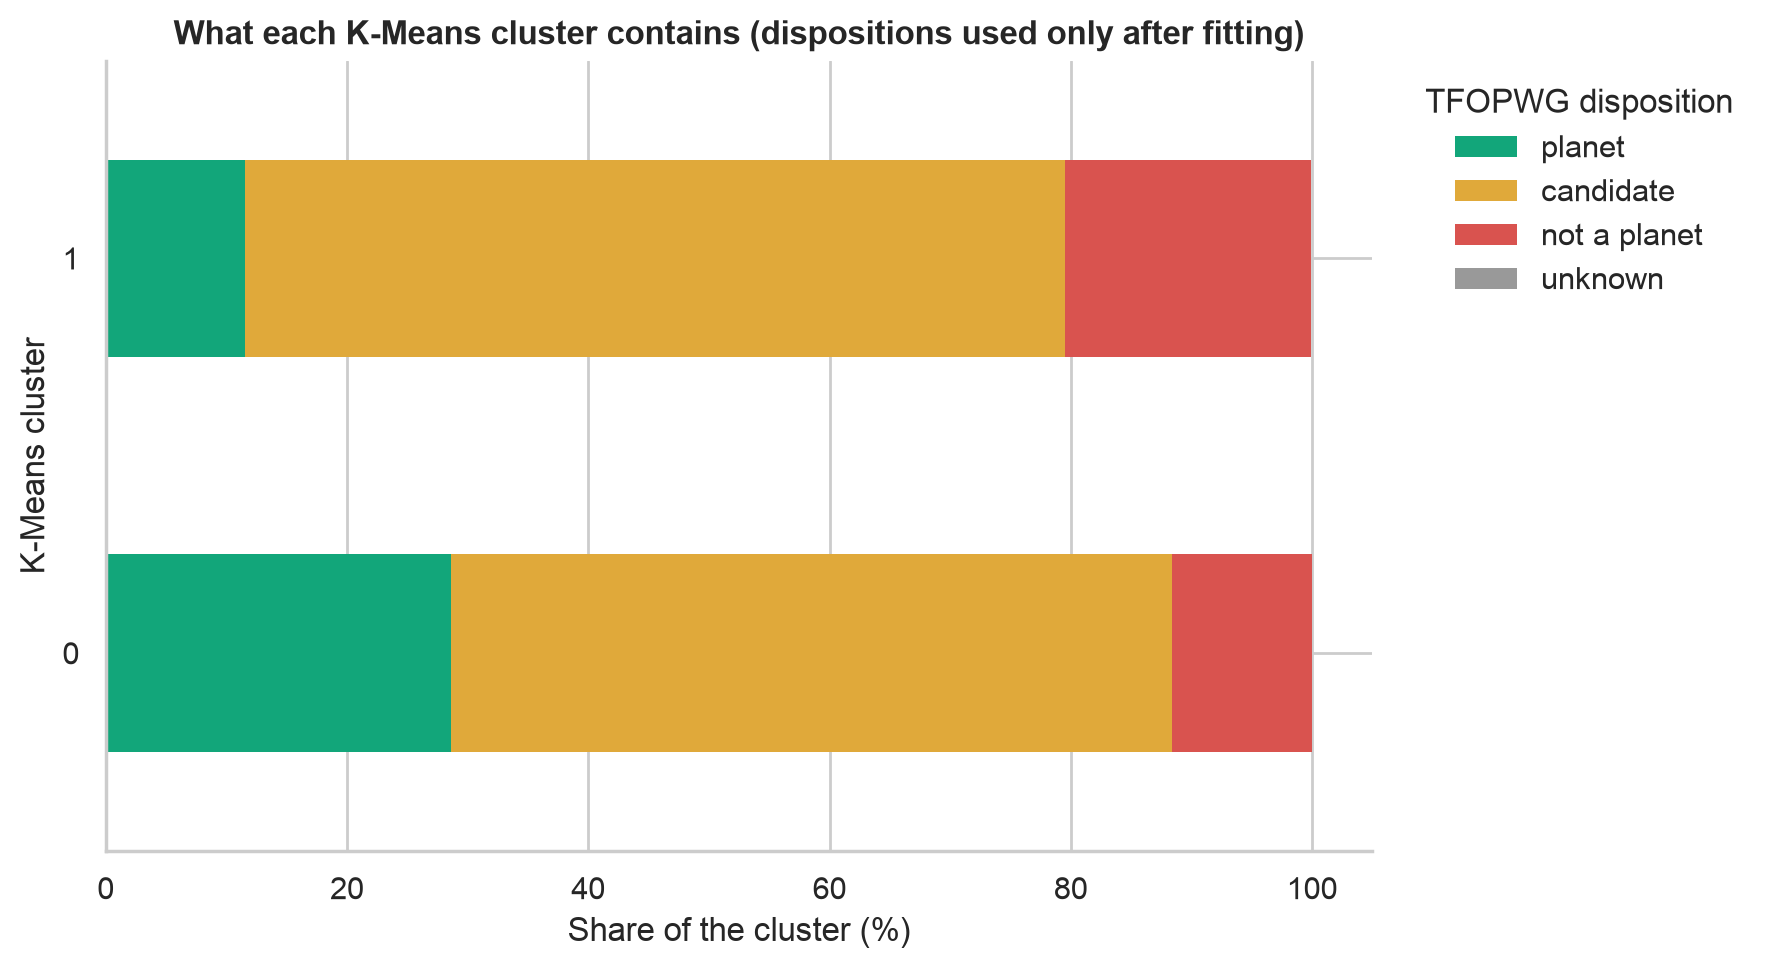

tfopwg_disp,APC,CP,FA,FP,KP,PC,missing
kmeans_cluster,,,,,,,
0,108,617,57,268,187,1570,0
1,380,197,43,1046,419,3254,2


In [11]:
#disposition groups: planets (confirmed + known), candidates (planet + ambiguous), not planets (false positive + false alarm)
group_map = {'CP': 'planet', 'KP': 'planet', 'PC': 'candidate', 'APC': 'candidate', 'FP': 'not a planet', 'FA': 'not a planet'}
disp_group = labels.map(group_map).fillna('unknown')

counts = pd.crosstab(km_labels, disp_group)
share = (pd.crosstab(km_labels, disp_group, normalize='index') * 100).round(1)
print("Rows per cluster and disposition group:")
display(counts)
print("Share of each cluster (%):")
display(share)

fig, ax = plt.subplots(figsize=(9, 5), dpi=200)
order = [c for c in ['planet', 'candidate', 'not a planet', 'unknown'] if c in share.columns]
share[order].plot(kind='barh', stacked=True, ax=ax, color=['#12a67a', '#e0a93a', '#d9534f', '#999999'][:len(order)], edgecolor='none')
ax.set_xlabel('Share of the cluster (%)')
ax.set_ylabel('K-Means cluster')
ax.set_title('What each K-Means cluster contains (dispositions used only after fitting)', fontsize=12, fontweight='bold')
ax.legend(title='TFOPWG disposition', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig('figures/K-Means/clusters_vs_disposition.png', dpi=300, bbox_inches='tight')
plt.show()

#fine-grained view for the viva
pd.crosstab(km_labels, labels.fillna('missing'))

k = 4 cluster sizes: {0: 3602, 1: 983, 2: 1966, 3: 1597}


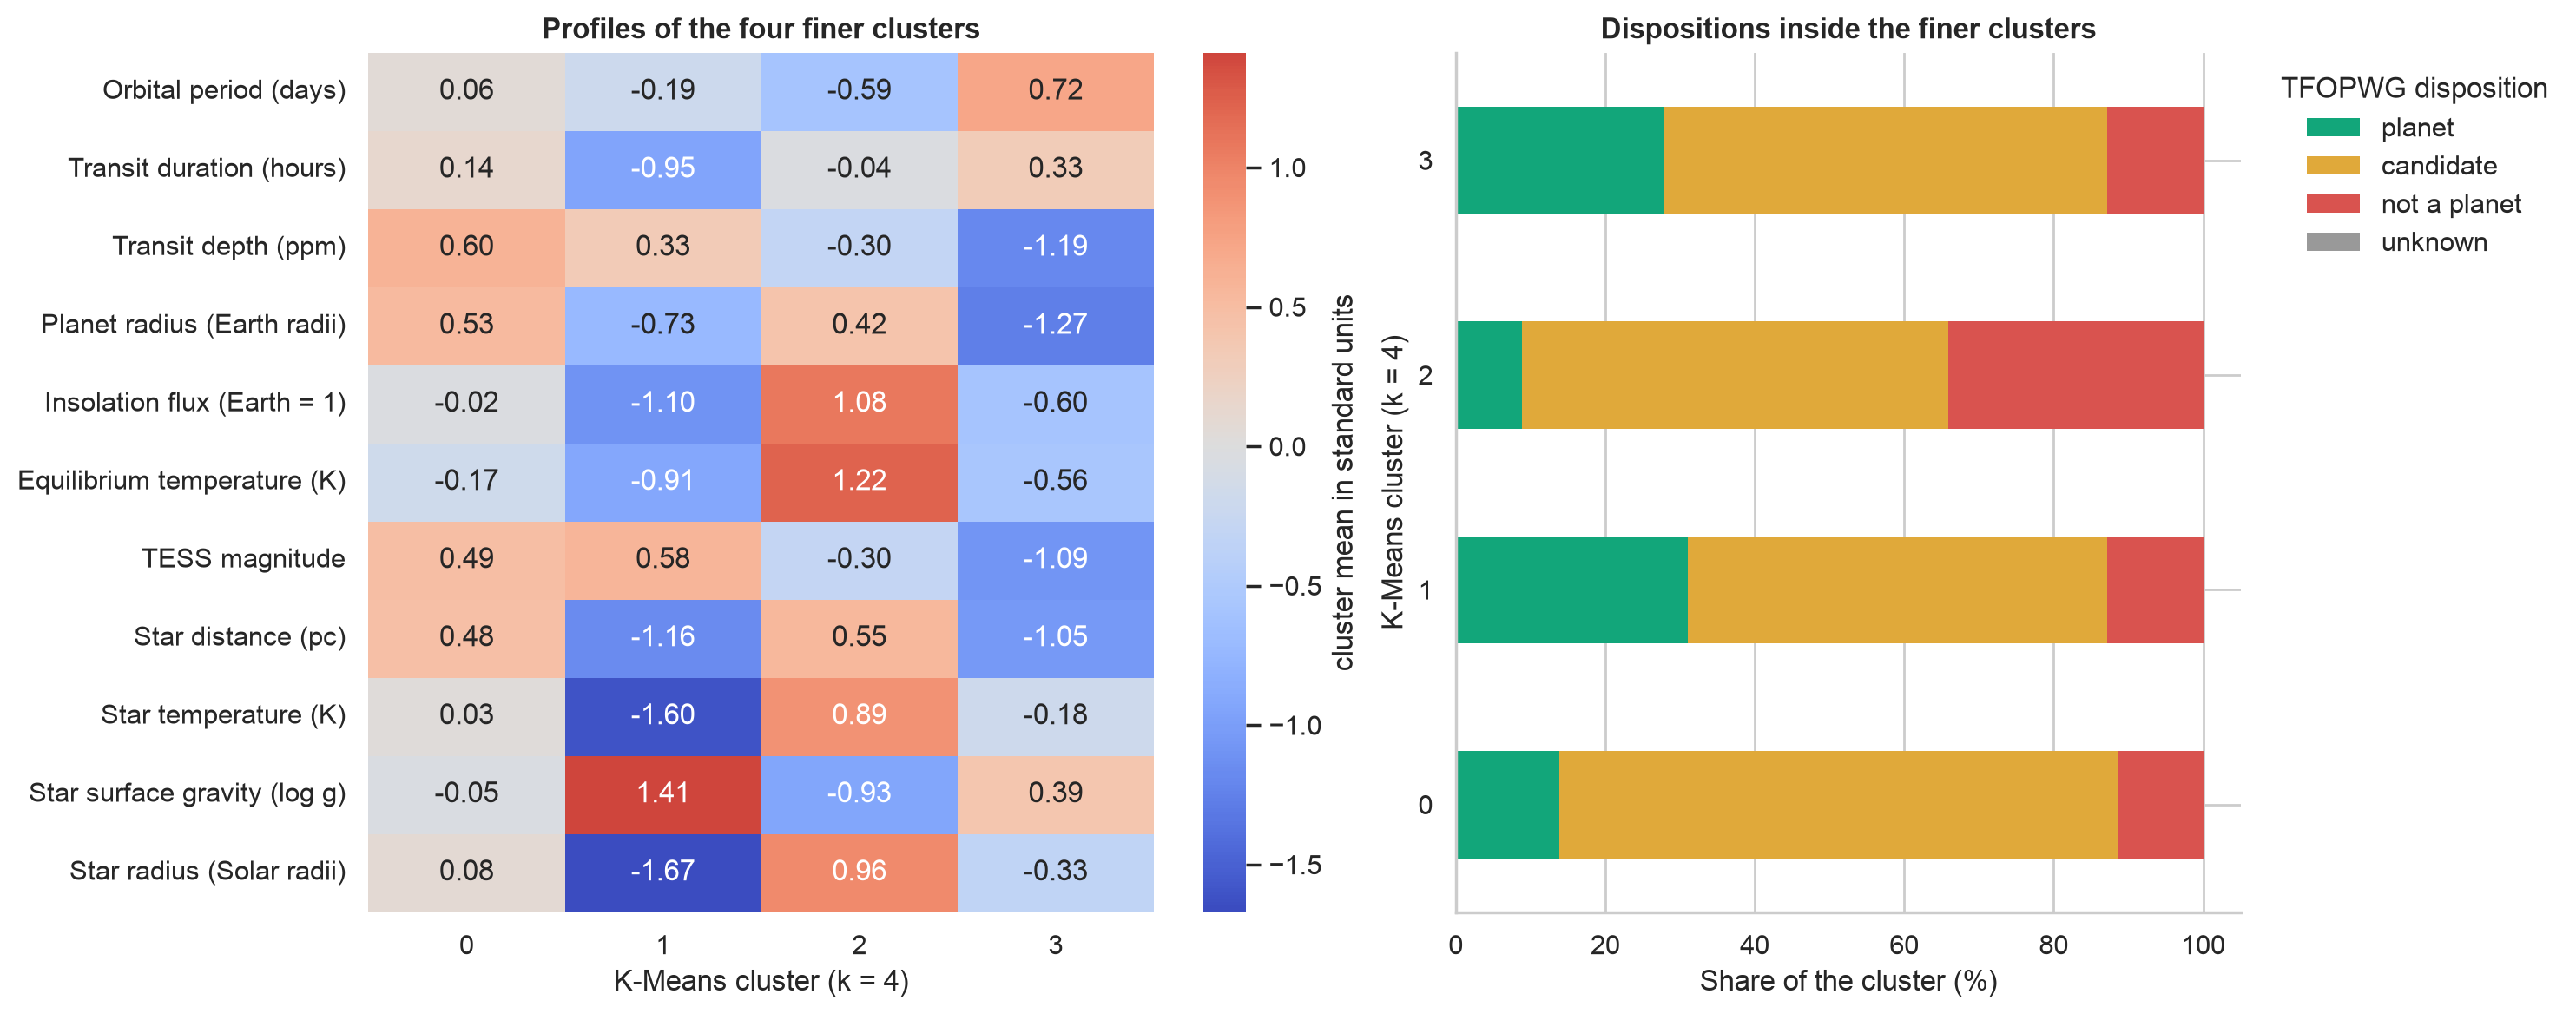

,cluster 0,cluster 1,cluster 2,cluster 3
Orbital period (days),4.34,3.58,2.63,9.40
Transit duration (hours),2.92,1.60,2.77,3.20
Transit depth (ppm),8866.00,5510.00,3010.00,820.00
Planet radius (Earth radii),12.63,5.01,12.69,2.83
Insolation flux (Earth = 1),356.29,34.44,2573.75,107.11
Equilibrium temperature (K),1178.98,651.09,1942.00,857.95
TESS magnitude,12.60,12.50,11.18,10.00
Star distance (pc),533.24,118.50,574.57,130.41
Star temperature (K),5804.00,3770.00,6455.55,5608.00
Star surface gravity (log g),4.30,4.67,4.05,4.46


tfopwg_disp,candidate,not a planet,planet,unknown
row_0,,,,
0,74.8,11.4,13.8,0.1
1,56.2,12.8,31.0,0.0
2,57.0,34.1,8.9,0.0
3,59.2,12.9,27.9,0.0


In [12]:
#finer view: the second silhouette peak at k = 4, fitted only to read the structure, the reported model stays k = 2
km4 = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(X)
km4_labels = pd.Series(km4.labels_, index=X.index)
print("k = 4 cluster sizes:", km4_labels.value_counts().sort_index().to_dict())

profile4 = X_raw.assign(cluster=km4_labels).groupby('cluster').median().T
profile4.index = [FEATURES[c] for c in profile4.index]
profile4.columns = [f'cluster {c}' for c in profile4.columns]
share4 = (pd.crosstab(km4_labels, disp_group, normalize='index') * 100).round(1)

zmeans4 = X.assign(cluster=km4_labels).groupby('cluster').mean().T
zmeans4.index = [FEATURES[c] for c in zmeans4.index]
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=200, gridspec_kw={'width_ratios': [1.25, 1]})
sns.heatmap(zmeans4, annot=True, fmt='.2f', cmap='coolwarm', center=0, cbar_kws={'label': 'cluster mean in standard units'}, ax=axes[0])
axes[0].set_xlabel('K-Means cluster (k = 4)')
axes[0].set_title('Profiles of the four finer clusters', fontsize=12, fontweight='bold')
share4[order].plot(kind='barh', stacked=True, ax=axes[1], color=['#12a67a', '#e0a93a', '#d9534f', '#999999'][:len(order)], edgecolor='none')
axes[1].set_xlabel('Share of the cluster (%)')
axes[1].set_ylabel('K-Means cluster (k = 4)')
axes[1].set_title('Dispositions inside the finer clusters', fontsize=12, fontweight='bold')
axes[1].legend(title='TFOPWG disposition', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
sns.despine(ax=axes[1])
plt.tight_layout()
plt.savefig('figures/K-Means/finer_view_k4.png', dpi=300, bbox_inches='tight')
plt.show()
display(profile4.round(2))
share4

**Observation (C4):** **Cluster 0 (2,807 TOIs, 34%)** is the small-planet group: median planet radius 3.5 Earth radii, transit depth 1,700 ppm, insolation 56 times Earth's and equilibrium temperature 740 K, around nearby (137 pc), cool (5,080 K), compact (0.82 solar radii, log g 4.53) stars. **Cluster 1 (5,341 TOIs, 66%)** is the giant-signal group: 12.7 Earth radii, 6,065 ppm, insolation 796, 1,440 K, around distant (557 pc), hotter (6,050 K), larger (1.52 solar radii) stars. The profile heatmap shows the split runs through every feature except transit duration, so it is one broad divide, not a cut on a single variable.

Read against the dispositions, cluster 0 holds 28.6% confirmed or known planets against 11.5% in cluster 1, and cluster 1 holds 20.4% false positives or alarms against 11.6%. In counts: 617 of the 814 confirmed planets sit in the small cluster, while 1,046 of the 1,314 false positives sit in the giant one, where eclipsing binaries mimic Jupiter-sized transits. Known planets lean the other way (419 of 606 in cluster 1) because most were hot Jupiters found by ground surveys before TESS. Candidates make up 60 to 68% of both clusters, so clusters are not dispositions: the measurements separate small planets from giant-sized signals, and the disposition depends on follow-up work that the table does not contain.

The finer k = 4 view splits the same picture by host star: small planets around nearby Sun-like stars (about 28% confirmed), small planets around cool red dwarfs (about 31% confirmed, the richest group), giant signals around Sun-like stars some 500 pc away (three quarters still unresolved candidates), and strongly irradiated giants around hot, large stars (about a third not planets, the eclipsing-binary corner). It is a sensible astrophysical map, but its silhouette (0.21) is lower than at k = 2, so k = 2 stays the reported model.

## Section D - Agglomerative Hierarchical Clustering

_Teammate's section._ It should reuse `X` from Section B, show the dendrogram, compare linkage strategies (ward, complete, average), fit the final model, and register its result with `score_clustering('Agglomerative', agg_labels)` so Sections E and F pick it up automatically. The t-SNE plot also belongs here.

## Section E - Metrics Comparison

The three required internal metrics for every algorithm registered above. Silhouette and Calinski-Harabasz are higher-is-better, Davies-Bouldin is lower-is-better.

,Algorithm,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means,2,0.2752,1.5022,2967.3419


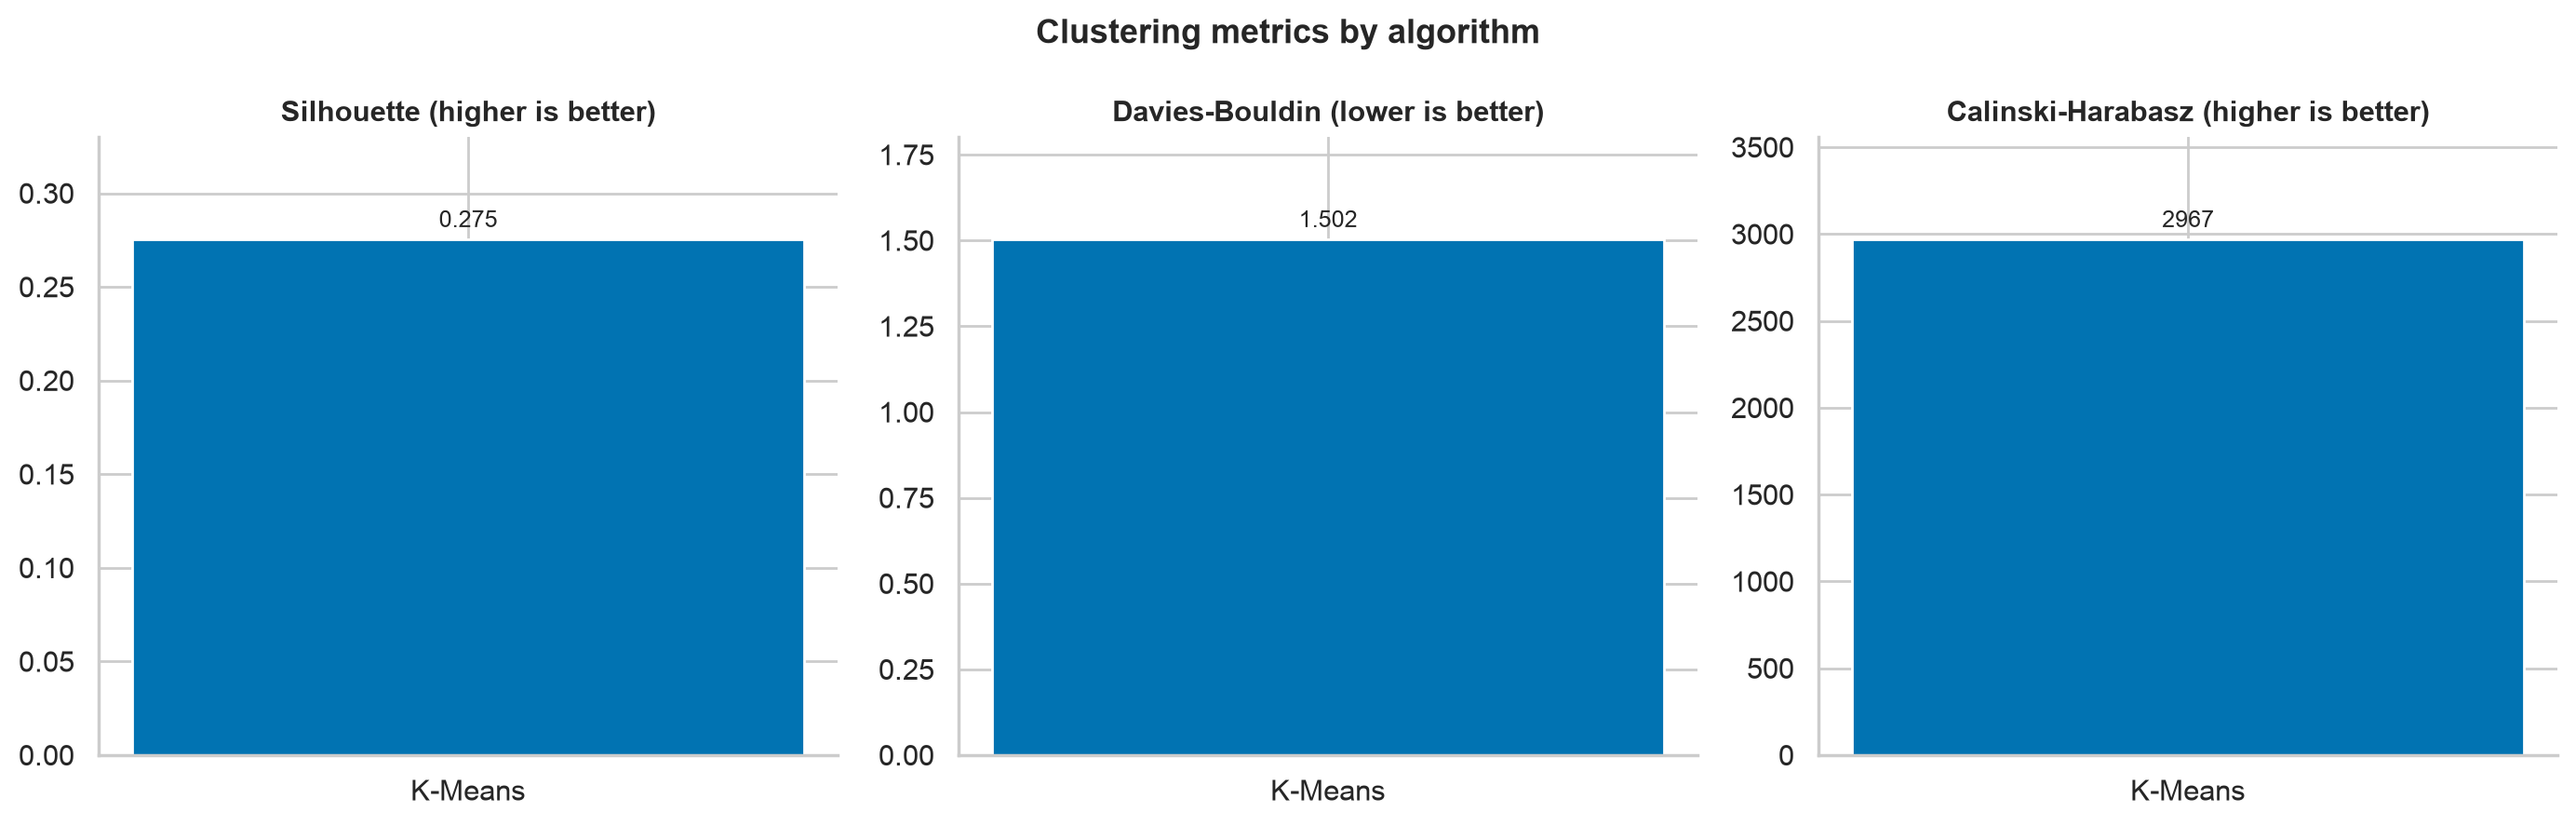

In [13]:
results_df = pd.DataFrame(cluster_results).sort_values('Silhouette', ascending=False).reset_index(drop=True)
display(results_df.round(4))

os.makedirs('figures/Comparison', exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), dpi=200)
for ax, (metric, better) in zip(axes, [('Silhouette', 'higher is better'), ('Davies-Bouldin', 'lower is better'), ('Calinski-Harabasz', 'higher is better')]):
    bars = ax.bar(results_df['Algorithm'], results_df[metric], color=sns.color_palette('colorblind', len(results_df)), width=0.55)
    ax.bar_label(bars, fmt='%.3f' if metric != 'Calinski-Harabasz' else '%.0f', padding=3, fontsize=9)
    ax.set_title(f'{metric} ({better})', fontsize=11, fontweight='bold')
    ax.set_ylim(0, results_df[metric].max() * 1.2)
    sns.despine(ax=ax)
fig.suptitle('Clustering metrics by algorithm', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/Comparison/clustering_metrics.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation (E):** With one algorithm registered so far the table has a single row: K-Means at k = 2 scores silhouette 0.275, Davies-Bouldin 1.50 and Calinski-Harabasz 2,967. A silhouette of about 0.28 means the two groups are real but overlap along a soft boundary, which the PCA plot in Section F confirms. The Agglomerative row appears here automatically once Section D registers it, and the two algorithms are then compared on all three metrics on the same scaled data.

## Section F - PCA Cluster Visualisation for Every Algorithm

The same two principal components from Section C, coloured by each algorithm's cluster labels, so the algorithms can be compared on one picture. The right-hand panel shows the dispositions on the same axes, again only as an after-the-fact check.

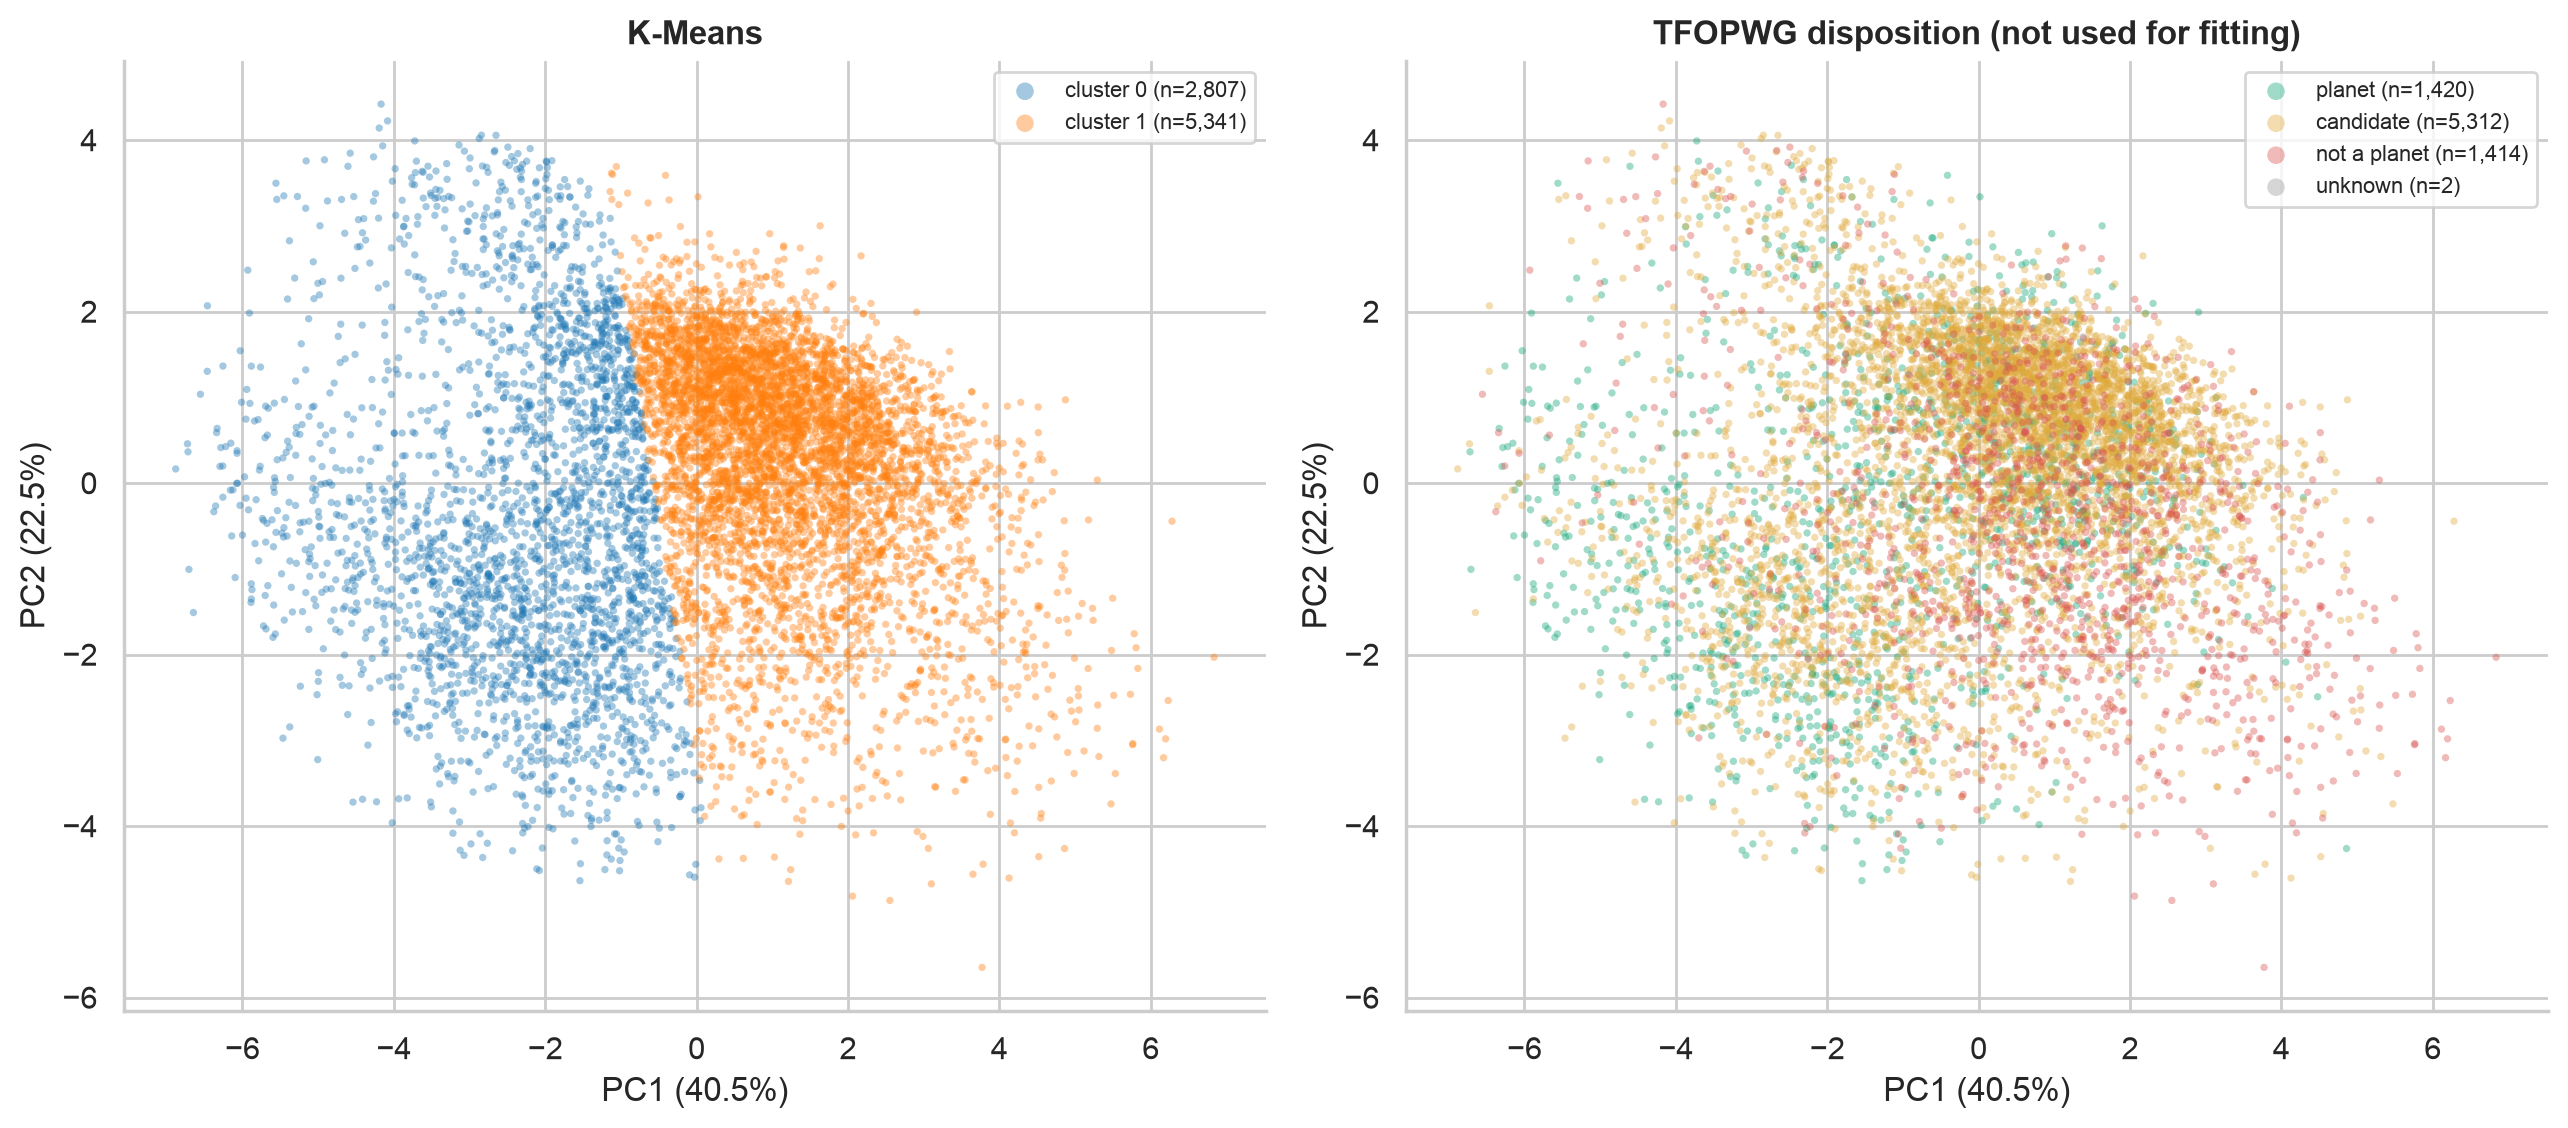

In [14]:
DISP_COLORS = {'planet': '#12a67a', 'candidate': '#e0a93a', 'not a planet': '#d9534f', 'unknown': '#999999'}
panels = list(cluster_labels.items()) + [('TFOPWG disposition (not used for fitting)', disp_group)]
fig, axes = plt.subplots(1, len(panels), figsize=(6.5 * len(panels), 5.8), dpi=200, squeeze=False)
for ax, (name, lab) in zip(axes[0], panels):
    lab = pd.Series(lab, index=X.index)
    if name in cluster_labels:
        cats = sorted(lab.unique())
        colors = sns.color_palette('tab10', len(cats))
    else:
        cats = [c for c in DISP_COLORS if c in lab.unique()]
        colors = [DISP_COLORS[c] for c in cats]
    for color, cat in zip(colors, cats):
        m = lab == cat
        label = f'cluster {cat}' if name in cluster_labels else str(cat)
        ax.scatter(X_pca[m, 0], X_pca[m, 1], s=7, alpha=0.4, color=color, edgecolor='none', label=f'{label} (n={m.sum():,})')
    ax.set_xlabel(f'PC1 ({ev[0]:.1f}%)')
    ax.set_ylabel(f'PC2 ({ev[1]:.1f}%)')
    ax.set_title(name, fontsize=12, fontweight='bold')
    leg = ax.legend(fontsize=8, frameon=True)
    for handle in leg.legend_handles:
        handle.set_sizes([40])
    sns.despine(ax=ax)
plt.tight_layout()
plt.savefig('figures/Comparison/pca_all_algorithms.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation (F):** In PCA space the K-Means boundary is almost a vertical line near PC1 = -0.5, so the split runs along the first component, which loads on star size, distance and temperature, insolation and planet radius: small, cool, nearby systems on the left and big, hot, distant ones on the right. The right-hand panel shows why clustering cannot reproduce the dispositions: candidates cover the whole plane, while confirmed and known planets concentrate on the left and lower left, where cluster 0 sits, and false positives thin out towards the right and lower right, inside cluster 1. The clusters capture the physical divide that correlates with the disposition, not the disposition itself.